## Setup

In [ ]:
!pip install -q transformers
!pip install -q sentencepiece
!pip install -q jiwer
!pip install -q datasets
!pip install -q evaluate
!pip install -q -U accelerate

!pip install -q matplotlib
!pip install -q protobuf==3.20.1
!pip install -q tensorboard

In [ ]:
!pip install ipykernel -U --user --force-reinstall

: 

In [1]:
import torch
print(torch.cuda.is_available())


True


## Imports

In [2]:
import os
import torch
import evaluate
import numpy as np
import pandas as pd
import glob as glob
import torch.optim as optim
import matplotlib.pyplot as plt
import torchvision.transforms as transforms

from PIL import Image
from zipfile import ZipFile
from tqdm.notebook import tqdm
from dataclasses import dataclass
from torch.utils.data import Dataset
from urllib.request import urlretrieve
from transformers import (
    VisionEncoderDecoderModel, 
    TrOCRProcessor,
    AutoTokenizer,
    ViTFeatureExtractor,
    BertTokenizer,
    NllbTokenizer,
    Seq2SeqTrainer,
    Seq2SeqTrainingArguments,
    default_data_collator
)

block_plot = False
plt.rcParams['figure.figsize'] = (12, 9)

In [ ]:
bold = f"\033[1m"
reset = f"\033[0m"

In [3]:
def seed_everything(seed_value):
    np.random.seed(seed_value)
    torch.manual_seed(seed_value)
    torch.cuda.manual_seed_all(seed_value)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything(42)

In [4]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

## Download and Extract the Dataset

In [ ]:
# def download_and_unzip(url, save_path):
#     print(f"Downloading and extracting assets....", end="")

#     # Downloading zip file using urllib package.
#     urlretrieve(url, save_path)

#     try:
#         # Extracting zip file using the zipfile package.
#         with ZipFile(save_path) as z:
#             # Extract ZIP file contents in the same directory.
#             z.extractall(os.path.split(save_path)[0])

#         print("Done")

#     except Exception as e:
#         print("\nInvalid file.", e)

In [ ]:
# URL = r"https://www.dropbox.com/scl/fi/vyvr7jbdvu8o174mbqgde/scut_data.zip?rlkey=fs8axkpxunwu6if9a2su71kxs&dl=1"
# asset_zip_path = os.path.join(os.getcwd(), "scut_data.zip")
# # Download if asset ZIP does not exist.
# if not os.path.exists(asset_zip_path):
#     download_and_unzip(URL, asset_zip_path)

## Training and Dataset Configurations

In [5]:
@dataclass(frozen=True)
class TrainingConfig:
    BATCH_SIZE:    int = 8
    EPOCHS:        int = 25
    LEARNING_RATE: float = 0.00005

@dataclass(frozen=True)
class DatasetConfig:
    DATA_ROOT:     str = 'dataset'

@dataclass(frozen=True)
class ModelConfig:
    MODEL_NAME: str = 'microsoft/trocr-base-handwritten'

## The SCUT Dataset

The SCUT dataset that we are using contains a total of 7703 images. Out of these 6052 are training samples and 1651 are validation samples. Here is the directory structure of the `scut_data` directory after downloading and extracting it.

```
dataset/
├── data_train
├── data_test
├── data_train.txt
└── data_test.txt
```

In [ ]:
# def visualize(dataset_path):
#     plt.figure(figsize=(10, 3))
#     for i in range(15):
#         plt.subplot(3, 5, i+1)
#         all_images = os.listdir(f"{dataset_path}/data_train")
#         image = plt.imread(f"{dataset_path}/data_train/{all_images[i]}")
#         plt.imshow(image)
#         plt.axis('off')
#         plt.title(all_images[i].split('.')[0])
#     plt.show()

# visualize(DatasetConfig.DATA_ROOT)

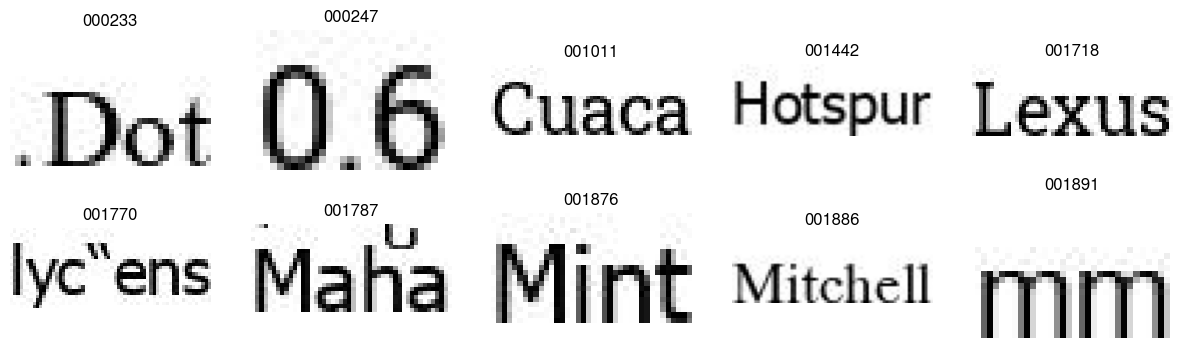

In [6]:
import matplotlib.pyplot as plt
import os

def visualize(dataset_path):
    plt.figure(figsize=(15, 4))
    for i in range(10):
        plt.subplot(2, 5, i+1)
        all_images = os.listdir(f"{dataset_path}/data_train")
        image = plt.imread(f"{dataset_path}/data_train/{all_images[i]}")
        plt.imshow(image)
        plt.axis('off')
        # Setting Khmer font
        plt.rcParams['font.family'] = 'Khmer OS'
        plt.title(all_images[i].split('.')[0], fontname='Khmer OS')
    plt.show()

visualize(DatasetConfig.DATA_ROOT)


## Prepare Dataset

In [7]:
train_df = pd.read_fwf(
    os.path.join(DatasetConfig.DATA_ROOT, 'data_train.txt'), header=None
)
train_df.rename(columns={0: 'file_name', 1: 'text'}, inplace=True)
test_df = pd.read_fwf(
    os.path.join(DatasetConfig.DATA_ROOT, 'data_test.txt'), header=None
)
test_df.rename(columns={0: 'file_name', 1: 'text'}, inplace=True)

In [ ]:
# train_df = pd.read_fwf(os.path.join(DatasetConfig.DATA_ROOT, 'data_train.txt'), header=None)
# train_df.rename(columns={0: 'file_name', 1: 'text'}, inplace=True)

# train_df.head()

In [59]:
train_df.head()

,file_name,text
0,000000.jpg,!(ម៉ានីល
1,000001.jpg,#១
2,000002.jpg,#២
3,000003.jpg,#៥
4,000004.jpg,$109


In [60]:
test_df.head()

,file_name,text
0,022567.jpg,!!!កាលបើ
1,022568.jpg,!Google
2,022569.jpg,$388
3,022570.jpg,$599
4,022571.jpg,(15)


In [ ]:
# Augmentations.
# train_transforms = transforms.Compose([
#     transforms.ColorJitter(brightness=.5, hue=.3),
#     transforms.GaussianBlur(kernel_size=(5, 9), sigma=(0.1, 5)),
# ])

In [87]:
# class CustomOCRDataset(Dataset):
#     def __init__(self, root_dir, df, processor, max_target_length=128):
#         self.root_dir = root_dir
#         self.df = df
#         self.processor = processor
#         self.max_target_length = max_target_length

#     def __len__(self):
#         return len(self.df)

#     def __getitem__(self, idx):
#         # The image file name.
#         file_name = self.df['file_name'][idx]
#         # The text (label).
#         text = self.df['text'][idx]
#         # Read the image, apply augmentations, and get the transformed pixels.
#         image = Image.open(self.root_dir + file_name).convert('RGB')
#         # image = train_transforms(image)
#         pixel_values = self.processor.feature_extractor(image, return_tensors='pt').pixel_values
#         # Pass the text through the tokenizer and get the labels,
#         # i.e. tokenized labels.
#         labels = self.processor.tokenizer(
#             text,
#             padding='max_length',
#             max_length=self.max_target_length
#         ).input_ids
#         # We are using -100 as the padding token.
#         labels = [label if label != self.processor.tokenizer.pad_token_id else -100 for label in labels]
#         encoding = {"pixel_values": pixel_values.squeeze(), "labels": torch.tensor(labels)}
#         return encoding

In [8]:
class CustomOCRDataset(Dataset):
    def __init__(self, root_dir, df, processor, max_target_length=128):
        self.root_dir = root_dir
        self.df = df
        self.processor = processor
        self.max_target_length = max_target_length

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        # The image file name.
        file_name = self.df['file_name'][idx]
        # The text (label).
        text = self.df['text'][idx]
        # Read the image, apply augmentations, and get the transformed pixels.
        image = Image.open(self.root_dir + file_name).convert('RGB')
        # image = train_transforms(image)
        pixel_values = self.processor(image, return_tensors='pt').pixel_values
        # Pass the text through the tokenizer and get the labels,
        # i.e. tokenized labels.
        labels = self.processor.tokenizer(
            text,
            padding='max_length',
            max_length=self.max_target_length
        ).input_ids
        # We are using -100 as the padding token.
        labels = [label if label != self.processor.tokenizer.pad_token_id else -100 for label in labels]
        encoding = {"pixel_values": pixel_values.squeeze(), "labels": torch.tensor(labels)}
        return encoding

In [11]:
# # Function to read vocabulary from a file
# def load_vocab(vocab_file):
#     with open(vocab_file, 'r', encoding='utf-8') as f:
#         vocab = f.read().splitlines()
#     return vocab

# # Path to your vocabulary file
# vocab_file = 'dataset/unique_words.txt'
# khmer_vocab = load_vocab(vocab_file)


In [8]:
# from transformers import AutoTokenizer

# # Step 1: Read the tokens from the text file
# with open('dataset/unique_words.txt', 'r', encoding='utf-8') as file:
#     khmer_vocab = file.read().splitlines()

# # Step 2: Convert the list of tokens into a dictionary
# khmer_special_tokens = {'additional_special_tokens': khmer_vocab}

# # Step 3: Load the tokenizer and add the special tokens
# tokenizer = AutoTokenizer.from_pretrained("xlm-roberta-base")
# tokenizer.add_special_tokens(khmer_special_tokens)

# # Verify if the special tokens were added
# print("Added special tokens:", tokenizer.special_tokens_map)

# tokenizer.save_pretrained('kh-xlm-roberta-base')


Added special tokens: {'bos_token': '<s>', 'eos_token': '</s>', 'unk_token': '<unk>', 'sep_token': '</s>', 'pad_token': '<pad>', 'cls_token': '<s>', 'mask_token': '<mask>', 'additional_special_tokens': ['!(ម៉ានីល', '#១', '#២', '#៥', '$109', '$169', '$320', '$369', '(1)', '(11)', '(13)', '(14)', '(2019', '(3)', '(360', '(4)', '(60X', '(64+8+2+2', '(AA)', '(ABS)', '(ACU)', '(AHB)', '(AICHR', '(AIMF)', '(ASEANAPOL', '(ATP)', '(Abdulla', '(Adhoc)', '(AgriTech)', '(Ajax)', '(Akihito)', '(American', '(Apple)', '(BA)', '(BBU)', '(Bayern', '(Benny', '(Bonus)', '(Bronze)', '(Bryce', '(CAG)', '(CAPJ)', '(CEO)', '(CHENG', '(CJCC)', '(Camsoc)', '(Chao', '(Chest', '(Chrysanthemum)', '(City', '(Cloud', '(DDC)', '(DSB)', '(Data', '(Digi)', '(Dortmund)', '(Dual', '(EDF)', '(EPC)', '(ESA)', '(ETSI)', '(EduTech)', '(Erling', '(FFC)', '(Fake', '(Fatih', '(Flash', '(Florida)', '(Forest', '(Frank', '(G)I-DLE', '(GM)', '(Gastronomy)', '(Gateway)', '(GovTech)', '(Guangxi', '(Gymnastic', '(HMS)', '(HR', '(Ham

('kh-xlm-roberta-base/tokenizer_config.json',
 'kh-xlm-roberta-base/special_tokens_map.json',
 'kh-xlm-roberta-base/sentencepiece.bpe.model',
 'kh-xlm-roberta-base/added_tokens.json',
 'kh-xlm-roberta-base/tokenizer.json')

In [9]:
# tokenizer = BertTokenizer.from_pretrained("bert-base-multilingual-cased", vocab_file="pretrained_model/bert_module_khmer/assets/vocab_file_BERT_.txt")
# tokenizer = NllbTokenizer.from_pretrained("facebook/nllb-200-distilled-600M") # my modified code


# feature_extractor = ViTFeatureExtractor.from_pretrained(ModelConfig.MODEL_NAME)
tokenizer = AutoTokenizer.from_pretrained("xlm-roberta-base")
feature_extractor = ViTFeatureExtractor.from_pretrained(ModelConfig.MODEL_NAME)

processor = TrOCRProcessor(feature_extractor=feature_extractor, tokenizer=tokenizer)
# processor = TrOCRProcessor.from_pretrained(ModelConfig.MODEL_NAME)
train_dataset = CustomOCRDataset(
    root_dir=os.path.join(DatasetConfig.DATA_ROOT, 'data_train/'),
    df=train_df,
    processor=processor
)
valid_dataset = CustomOCRDataset(
    root_dir=os.path.join(DatasetConfig.DATA_ROOT, 'data_test/'),
    df=test_df,
    processor=processor
)

/home/EmHengly/miniconda3/envs/khocr/lib/python3.10/site-packages/transformers/models/vit/feature_extraction_vit.py:28: FutureWarning: The class ViTFeatureExtractor is deprecated and will be removed in version 5 of Transformers. Please use ViTImageProcessor instead.
  warnings.warn(
/home/EmHengly/miniconda3/envs/khocr/lib/python3.10/site-packages/transformers/models/trocr/processing_trocr.py:46: FutureWarning: The `feature_extractor` argument is deprecated and will be removed in v5, use `image_processor` instead.
  warnings.warn(


In [ ]:
# from transformers import BertTokenizer

# # Initialize a Khmer tokenizer (e.g., BERT-based)
# tokenizer = BertTokenizer.from_pretrained("aubmindlab/khbert-base")

# # Khmer text to tokenize
# khmer_text = "សុខ ពិសី លាភ"

# # Tokenize Khmer text
# tokenized_text = tokenizer.encode(khmer_text)

# # Decode tokenized sequence
# decoded_text = tokenizer.decode(tokenized_text)

# print("Tokenized text:", tokenized_text)
# print("Decoded text:", decoded_text)


In [35]:
id =processor.tokenizer.tokenize('ខ្ញុំ')
print(id)

['ខ្ញុំ']


In [10]:
encode = tokenizer.tokenize('មិត្តភក្ដិ')
print (encode)

['▁', 'មិត្ត', 'ភ', 'ក្', 'ដ', 'ិ']


In [11]:
id = processor.tokenizer.encode('មិត្តភក្ដិ')

print("id: ", id)

id:  [0, 6, 101213, 37551, 31171, 11381, 13640, 2]


In [12]:
decode = processor.tokenizer.decode(id) 
print("decode:",decode )

decode: <s> មិត្តភក្ដិ</s>


In [9]:
print("Number of training examples:", len(train_dataset))
print("Number of validation examples:", len(valid_dataset))

Number of training examples: 22567
Number of validation examples: 5640


In [10]:
encoding = train_dataset[0]
for k,v in encoding.items():
    print(k, v.shape)

pixel_values torch.Size([3, 384, 384])
labels torch.Size([128])


(-0.5, 75.5, 25.5, -0.5)

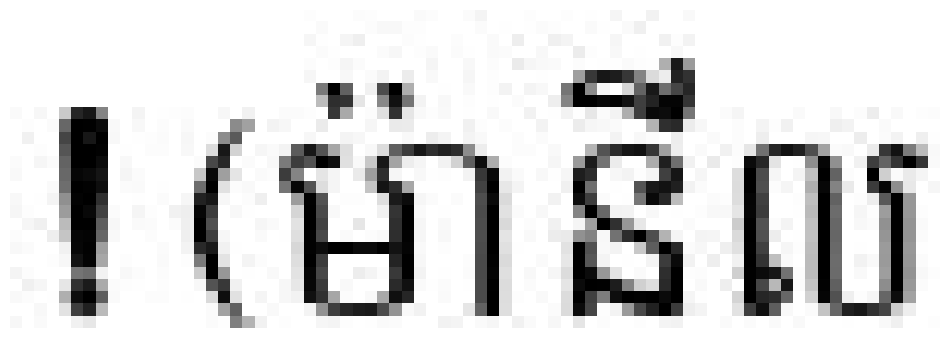

In [15]:
image = Image.open(train_dataset.root_dir + train_df['file_name'][0]).convert("RGB")
# image = train_transforms(image)
plt.imshow(image)
plt.axis('off')

In [11]:
labels = encoding['labels']
labels[labels == -100] = processor.tokenizer.pad_token_id
label_str = processor.decode(labels, skip_special_tokens=True)
print(label_str)

!(ម៉ានីល


In [92]:
# labels = encoding['labels']

# # Replace -100 with pad token id
# labels[labels == -100] = processor.tokenizer.pad_token_id

# # Decode labels
# label_str = processor.tokenizer.decode(labels, skip_special_tokens=True)

# print(label_str)


ម៉ានីល


In [11]:
# Check the tokenizer vocabulary size
vocab_size = processor.tokenizer.vocab_size
print(f"Tokenizer vocabulary size: {vocab_size}")

Tokenizer vocabulary size: 250002


In [54]:
# Example usage assuming `df` is your DataFrame and `processor` is your processor object
# Initialize dataset
dataset = CustomOCRDataset(root_dir='dataset/data_train/', df=train_df, processor=processor, max_target_length=32)

# Example: Print label IDs for the first example in the dataset
print(dataset[1])


{'pixel_values': tensor([[[1.0000, 1.0000, 1.0000,  ..., 0.9922, 0.9922, 0.9922],
         [1.0000, 1.0000, 1.0000,  ..., 0.9922, 0.9922, 0.9922],
         [1.0000, 1.0000, 1.0000,  ..., 0.9922, 0.9922, 0.9922],
         ...,
         [1.0000, 1.0000, 1.0000,  ..., 0.9686, 0.9686, 0.9686],
         [1.0000, 1.0000, 1.0000,  ..., 0.9686, 0.9686, 0.9686],
         [1.0000, 1.0000, 1.0000,  ..., 0.9686, 0.9686, 0.9686]],

        [[1.0000, 1.0000, 1.0000,  ..., 0.9922, 0.9922, 0.9922],
         [1.0000, 1.0000, 1.0000,  ..., 0.9922, 0.9922, 0.9922],
         [1.0000, 1.0000, 1.0000,  ..., 0.9922, 0.9922, 0.9922],
         ...,
         [1.0000, 1.0000, 1.0000,  ..., 0.9686, 0.9686, 0.9686],
         [1.0000, 1.0000, 1.0000,  ..., 0.9686, 0.9686, 0.9686],
         [1.0000, 1.0000, 1.0000,  ..., 0.9686, 0.9686, 0.9686]],

        [[1.0000, 1.0000, 1.0000,  ..., 0.9922, 0.9922, 0.9922],
         [1.0000, 1.0000, 1.0000,  ..., 0.9922, 0.9922, 0.9922],
         [1.0000, 1.0000, 1.0000,  ..., 0

In [55]:
from transformers import NllbTokenizer

# Example token IDs (replace with actual token IDs from your dataset)
token_ids = [ 0,   468, 27954,     2,  -100,  -100,  -100]

# Load the tokenizer used in your CustomOCRDataset
# tokenizer = AutoTokenizer.from_pretrained("khmer_tokenizer")
# tokenizer = AutoTokenizer.from_pretrained("GKLMIP/bert-khmer-small-uncased-tokenized")

# Ensure all token IDs are valid
valid_token_ids = [tid for tid in token_ids if tid != -100]

# Decode token IDs to text
decoded_text = processor.batch_decode(valid_token_ids, skip_special_tokens=True)

print("Decoded Text:", decoded_text)


Decoded Text: ['', '#', '១', '']


## Initialize the Model

In [12]:
model = VisionEncoderDecoderModel.from_pretrained(ModelConfig.MODEL_NAME, )
model.to(device)
print(model)
# Total parameters and trainable parameters.
total_params = sum(p.numel() for p in model.parameters())
print(f"{total_params:,} total parameters.")
total_trainable_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad)
print(f"{total_trainable_params:,} training parameters.")

Some weights of VisionEncoderDecoderModel were not initialized from the model checkpoint at microsoft/trocr-base-handwritten and are newly initialized: ['encoder.pooler.dense.bias', 'encoder.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


VisionEncoderDecoderModel(
  (encoder): ViTModel(
    (embeddings): ViTEmbeddings(
      (patch_embeddings): ViTPatchEmbeddings(
        (projection): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
      )
      (dropout): Dropout(p=0.0, inplace=False)
    )
    (encoder): ViTEncoder(
      (layer): ModuleList(
        (0-11): 12 x ViTLayer(
          (attention): ViTAttention(
            (attention): ViTSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=False)
              (key): Linear(in_features=768, out_features=768, bias=False)
              (value): Linear(in_features=768, out_features=768, bias=False)
              (dropout): Dropout(p=0.0, inplace=False)
            )
            (output): ViTSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.0, inplace=False)
            )
          )
          (intermediate): ViTIntermediate(
            (dense): Linear(in_fea

In [13]:
# Resize token embeddings if necessary
model.decoder.resize_token_embeddings(len(tokenizer))

Embedding(250002, 1024)

In [14]:
print(model.config)

VisionEncoderDecoderConfig {
  "_name_or_path": "microsoft/trocr-small-printed",
  "architectures": [
    "VisionEncoderDecoderModel"
  ],
  "decoder": {
    "_name_or_path": "",
    "activation_dropout": 0.0,
    "activation_function": "relu",
    "add_cross_attention": true,
    "architectures": null,
    "attention_dropout": 0.0,
    "bad_words_ids": null,
    "begin_suppress_tokens": null,
    "bos_token_id": 0,
    "chunk_size_feed_forward": 0,
    "classifier_dropout": 0.0,
    "cross_attention_hidden_size": 384,
    "d_model": 256,
    "decoder_attention_heads": 8,
    "decoder_ffn_dim": 1024,
    "decoder_layerdrop": 0.0,
    "decoder_layers": 6,
    "decoder_start_token_id": 2,
    "diversity_penalty": 0.0,
    "do_sample": false,
    "dropout": 0.1,
    "early_stopping": false,
    "encoder_no_repeat_ngram_size": 0,
    "eos_token_id": 2,
    "exponential_decay_length_penalty": null,
    "finetuning_task": null,
    "forced_bos_token_id": null,
    "forced_eos_token_id": null

## Model Configurations

In [14]:
# Set special tokens used for creating the decoder_input_ids from the labels.
model.config.decoder_start_token_id = processor.tokenizer.cls_token_id
model.config.pad_token_id = processor.tokenizer.pad_token_id
# Set Correct vocab size.
model.config.vocab_size = model.config.decoder.vocab_size
model.config.eos_token_id = processor.tokenizer.sep_token_id

# model.config.max_length = 64
# model.config.early_stopping = True
# model.config.no_repeat_ngram_size = 3
# model.config.length_penalty = 2.0
# model.config.num_beams = 4

We use the AdamW optimizer here with a weight decay of 0.0005.

In [15]:
optimizer = optim.AdamW(
    model.parameters(), lr=TrainingConfig.LEARNING_RATE, weight_decay=0.0005
)

## Evaluation Metric

In [16]:
cer_metric = evaluate.load('cer')

In [18]:
# def compute_cer(pred):
#     labels_ids = pred.label_ids
#     pred_ids = pred.predictions

#     pred_str = processor.batch_decode(pred_ids, skip_special_tokens=True)
#     labels_ids[labels_ids == -100] = processor.tokenizer.pad_token_id
#     label_str = processor.batch_decode(labels_ids, skip_special_tokens=True)

#     cer = cer_metric.compute(predictions=pred_str, references=label_str)

#     return {"cer": cer}

In [17]:
def compute_cer(pred):
    labels_ids = pred.label_ids
    pred_ids = pred.predictions

    # Decode the predictions and labels
    pred_str = processor.batch_decode(pred_ids, skip_special_tokens=True)
    labels_ids[labels_ids == -100] = processor.tokenizer.pad_token_id
    label_str = processor.batch_decode(labels_ids, skip_special_tokens=True)

    # Check for empty strings in predictions and labels
    empty_label_indices = [i for i, l in enumerate(label_str) if not l]

    if empty_label_indices:
        print(f"Empty labels found at indices: {empty_label_indices}")

    # Filter out empty labels and corresponding predictions
    filtered_pred_str = [p for i, p in enumerate(pred_str) if i not in empty_label_indices]
    filtered_label_str = [l for l in label_str if l]

    # Ensure that the lengths of predictions and labels match after filtering
    if len(filtered_pred_str) != len(filtered_label_str):
        raise ValueError("Mismatch between number of predictions and labels after removing empty strings.")

    # Compute CER
    cer = cer_metric.compute(predictions=filtered_pred_str, references=filtered_label_str)

    return {"cer": cer}


## Training and Validation Loops

In [18]:
training_args = Seq2SeqTrainingArguments(
    predict_with_generate=True,
    evaluation_strategy='epoch',
    per_device_train_batch_size=TrainingConfig.BATCH_SIZE,
    per_device_eval_batch_size=TrainingConfig.BATCH_SIZE,
    fp16=False,
    output_dir='ocrmodel-xlm-roberta/',
    logging_strategy='epoch',
    save_strategy='epoch',
    save_total_limit=5,
    report_to='tensorboard',
    num_train_epochs=TrainingConfig.EPOCHS
)

/home/EmHengly/miniconda3/envs/khocr/lib/python3.10/site-packages/transformers/training_args.py:1474: FutureWarning: `evaluation_strategy` is deprecated and will be removed in version 4.46 of 🤗 Transformers. Use `eval_strategy` instead
  warnings.warn(


In [19]:
# Initialize trainer.
trainer = Seq2SeqTrainer(
    model=model,
    tokenizer=processor.tokenizer,
    args=training_args,
    compute_metrics=compute_cer,
    train_dataset=train_dataset,
    eval_dataset=valid_dataset,
    data_collator=default_data_collator
)

## Train

In [21]:
res = trainer.train()

/home/EmHengly/.local/lib/python3.10/site-packages/torch/nn/parallel/_functions.py:68: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  warnings.warn('Was asked to gather along dimension 0, but all '


Epoch,Training Loss,Validation Loss,Cer
1,4.052300,3.578422,0.963506
2,3.371400,3.354822,0.931485
3,3.077400,3.101398,0.909302
4,2.602400,2.462707,0.785569
5,1.908800,1.933952,0.588790
6,1.347000,1.549843,0.442188
7,1.042400,1.274480,0.331634
8,0.778900,1.152218,0.292218
9,0.554200,1.113534,0.247346
10,0.407200,1.023732,0.225850


/home/EmHengly/miniconda3/envs/khocr/lib/python3.10/site-packages/transformers/generation/utils.py:1168: UserWarning: Using the model-agnostic default `max_length` (=20) to control the generation length. We recommend setting `max_new_tokens` to control the maximum length of the generation.
  warnings.warn(
/home/EmHengly/.local/lib/python3.10/site-packages/torch/nn/parallel/_functions.py:68: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  warnings.warn('Was asked to gather along dimension 0, but all '
/home/EmHengly/miniconda3/envs/khocr/lib/python3.10/site-packages/transformers/generation/utils.py:1168: UserWarning: Using the model-agnostic default `max_length` (=20) to control the generation length. We recommend setting `max_new_tokens` to control the maximum length of the generation.
  warnings.warn(
/home/EmHengly/.local/lib/python3.10/site-packages/torch/nn/parallel/_functions.py:68: UserWarning:

In [22]:
res

TrainOutput(global_step=35275, training_loss=0.8225015189578396, metrics={'train_runtime': 46881.7288, 'train_samples_per_second': 12.034, 'train_steps_per_second': 0.752, 'total_flos': 4.2216379763015025e+20, 'train_loss': 0.8225015189578396, 'epoch': 25.0})

## Inference

In [35]:
device = torch.device('cuda:0' if torch.cuda.is_available else 'cpu')

In [26]:
# processor = TrOCRProcessor.from_pretrained(ModelConfig.MODEL_NAME)
# trained_model = VisionEncoderDecoderModel.from_pretrained('ocrmodel-xlm-roberta/checkpoint-'+str(res.global_step)).to(device)

trained_model = VisionEncoderDecoderModel.from_pretrained('ocrmodel-xlm-roberta/checkpoint-35275').to(device)

In [27]:
from torch.utils.data import DataLoader

test_dataloader = DataLoader(valid_dataset, batch_size=16)

In [28]:
batch = next(iter(test_dataloader))

In [29]:
for k,v in batch.items():
  print(k, v.shape)

pixel_values torch.Size([16, 3, 384, 384])
labels torch.Size([16, 128])


In [30]:
labels = batch["labels"]
labels[labels == -100] = processor.tokenizer.pad_token_id
label_str = processor.batch_decode(labels, skip_special_tokens=True)
label_str

['!!!កាលបើ',
 '!Google',
 '$388',
 '$599',
 '(15)',
 '(21.9',
 '(Ajax)',
 '(Android',
 '(Chao',
 '(Congressional',
 '(EBD)',
 '(Enamel)',
 '(Endometriosis)',
 '(facebook)',
 '(Fintech)',
 '(GDP)']

In [ ]:
# cer_metric = evaluate.load('cer')

In [34]:
import numpy as np
import matplotlib.pyplot as plt
from difflib import SequenceMatcher

def compare_string(true_label, pred_label):
    
    true_label = true_label.replace(" ", "").replace('-','').replace('0','O')
    pred_label =  pred_label.replace(" ", "").replace('-','').replace('0','O')
    
    if pred_label == true_label:
        return True
    
    return False

In [ ]:
import torch
from PIL import Image
from difflib import SequenceMatcher
import matplotlib.pyplot as plt
import numpy as np
import os

# Update this path to match your dataset location
data_dir = "dataset/data_test/"

total_char = 0
correct = 0
correct_char = 0

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Set the model to evaluation mode
trained_model.eval()

def compare_string(str1, str2):
    # You can customize this function for your specific string comparison logic
    return str1 == str2

for _, val in test_df.iterrows():
    file_name = val['file_name']
    file_path = os.path.join(data_dir, file_name)
    
    # Print the file path for debugging
    print(f"Processing file: {file_path}")
    
    if not os.path.exists(file_path):
        print(f"File not found: {file_path}")
        continue
    
    try:
        image = Image.open(file_path).convert("RGB")
    except Exception as e:
        print(f"Error opening image {file_path}: {e}")
        continue
    
    pixel_values = processor(image, return_tensors="pt").pixel_values
    pixel_values = pixel_values.to(device)
    
    with torch.no_grad():
        generated_ids = trained_model.generate(pixel_values)
    
    pred_label = processor.batch_decode(generated_ids, skip_special_tokens=True)[0]
    true_label = val['text']
    
    # Calculate the total number of characters in the reference
    total_char += len(true_label)
    
    # Calculate the number of correct characters
    correct_char += SequenceMatcher(None, true_label, pred_label).ratio() * len(true_label)
    
    # Check if the prediction is correct
    if compare_string(true_label, pred_label):
        correct += 1
    else:
        plt.imshow(np.asarray(image))
        plt.show()
        print('true_label:', true_label)
        print('pred_label:', pred_label)

# Compute Character Error Rate (CER)
cer_score = 1 - (correct_char / total_char)

print(f"Final CER score: {cer_score}")
print(f"Correct predictions: {correct}/{len(test_df)}")


In [ ]:
import torch
from PIL import Image
from difflib import SequenceMatcher
import matplotlib.pyplot as plt
import numpy as np
import os

# Update this path to match your dataset location
data_dir = "/home/EmHengly/khmer_trocr/dataset/data_test/"

total_char = 0
correct = 0
correct_char = 0

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Set the model to evaluation mode and move it to the appropriate device
trained_model.to(device)
trained_model.eval()

def compare_string(str1, str2):
    # You can customize this function for your specific string comparison logic
    return str1 == str2

for _, val in test_df.iterrows():
    file_name = val['file_name']
    file_path = os.path.join(data_dir, file_name)
    
    # Print the file path for debugging
    print(f"Processing file: {file_path}")
    
    if not os.path.exists(file_path):
        print(f"File not found: {file_path}")
        continue
    
    try:
        image = Image.open(file_path).convert("RGB")
    except Exception as e:
        print(f"Error opening image {file_path}: {e}")
        continue
    
    pixel_values = processor(image, return_tensors="pt").pixel_values
    pixel_values = pixel_values.to(device)
    
    with torch.no_grad():
        generated_ids = trained_model.generate(pixel_values)
    
    pred_label = processor.batch_decode(generated_ids, skip_special_tokens=True)[0]
    true_label = val['text']
    
    # Calculate the total number of characters in the reference
    total_char += len(true_label)
    
    # Calculate the number of correct characters
    correct_char += SequenceMatcher(None, true_label, pred_label).ratio() * len(true_label)
    
    # Check if the prediction is correct
    if compare_string(true_label, pred_label):
        correct += 1
    else:
        # Move image data from GPU to CPU for plotting
        image_np = np.asarray(image)
        
        # Plot the image
        plt.imshow(image_np)
        plt.show()
        
        print('true_label:', true_label)
        print('pred_label:', pred_label)

# Compute Character Error Rate (CER)
cer_score = 1 - (correct_char / total_char)

print(f"Final CER score: {cer_score}")
print(f"Correct predictions: {correct}/{len(test_df)}")


In [32]:
from tqdm.notebook import tqdm
import torch
from datasets import load_metric

print("Running evaluation...")

# Ensure the model is in evaluation mode
trained_model.eval()

# Device configuration
# device = "cuda" if torch.cuda.is_available() else "cpu"
# model.to(device)

# Initialize an empty list to collect predictions and labels
all_predictions = []
all_labels = []

# Load the CER metric
cer = evaluate.load('cer')

# Evaluation loop
for batch in tqdm(test_dataloader):
    # Predict using generate
    pixel_values = batch["pixel_values"].to(device)
    with torch.no_grad():
        outputs = model.generate(pixel_values)

    # Decode predictions and labels
    pred_str = processor.batch_decode(outputs, skip_special_tokens=True)
    labels = batch["labels"]
    labels[labels == -100] = processor.tokenizer.pad_token_id
    label_str = processor.batch_decode(labels, skip_special_tokens=True)

    # Filter out empty strings
    filtered_pred_str = [p for p in pred_str if p.strip()]
    filtered_label_str = [l for l in label_str if l.strip()]

    # Log mismatched cases
    if len(filtered_pred_str) != len(filtered_label_str):
        print(f"Mismatch found. Skipping this batch. Predictions: {len(filtered_pred_str)}, Labels: {len(filtered_label_str)}")
        continue

    # Add filtered predictions and labels to the lists
    all_predictions.extend(filtered_pred_str)
    all_labels.extend(filtered_label_str)

# Compute CER
cer.add_batch(predictions=all_predictions, references=all_labels)
final_score = cer.compute()

print(f"Final CER score: {final_score}")


Running evaluation...


  0%|          | 0/353 [00:00<?, ?it/s]

Final CER score: 1.416279069767442


In [22]:
def read_and_show(image_path):
    """
    :param image_path: String, path to the input image.

    Returns:
        image: PIL Image.
    """
    image = Image.open(image_path).convert('RGB')
    return image

In [23]:
def ocr(image, processor, model):
    """
    :param image: PIL Image.
    :param processor: Huggingface OCR processor.
    :param model: Huggingface OCR model.

    Returns:
        generated_text: the OCR'd text string.
    """
    # We can directly perform OCR on cropped images.
    pixel_values = processor(image, return_tensors='pt').pixel_values.to(device)
    generated_ids = model.generate(pixel_values)
    generated_text = processor.batch_decode(generated_ids, skip_special_tokens=True)[0]
    return generated_text

In [24]:
def eval_new_data(
    data_path=os.path.join(DatasetConfig.DATA_ROOT, 'data_test', '*'),
    num_samples=50
):
    image_paths = glob.glob(data_path)
    for i, image_path in tqdm(enumerate(image_paths), total=len(image_paths)):
        if i == num_samples:
            break
        image = read_and_show(image_path)
        text = ocr(image, processor, trained_model)
        plt.figure(figsize=(7, 4))
        plt.imshow(image)
        # plt.title(text)
        plt.axis('off')
        plt.show()
        print('Generated text:', text)

  0%|          | 0/5640 [00:00<?, ?it/s]

/home/EmHengly/miniconda3/envs/khocr/lib/python3.10/site-packages/transformers/generation/utils.py:1168: UserWarning: Using the model-agnostic default `max_length` (=20) to control the generation length. We recommend setting `max_new_tokens` to control the maximum length of the generation.
  warnings.warn(


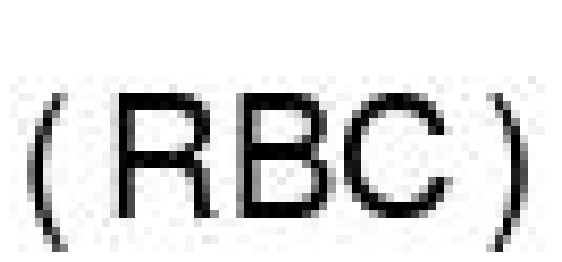

Generated text: (TRG)


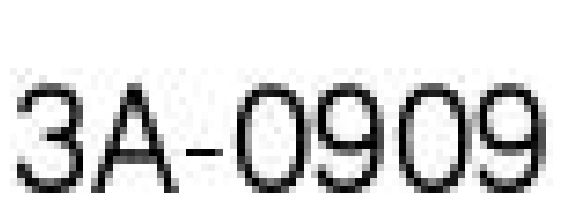

Generated text: 3C-58809


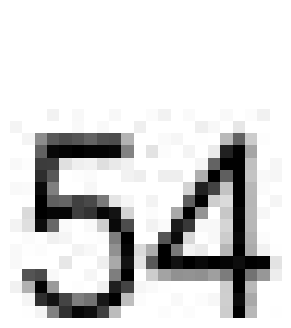

Generated text: 54


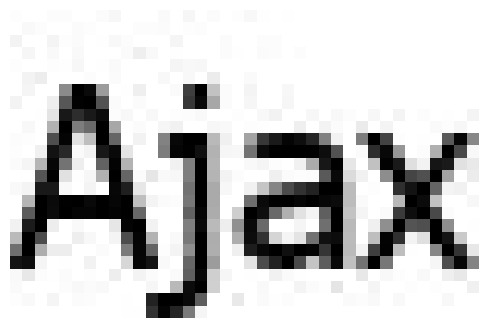

Generated text: Ajax


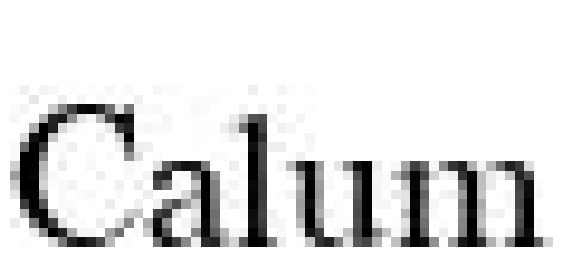

Generated text: Cha


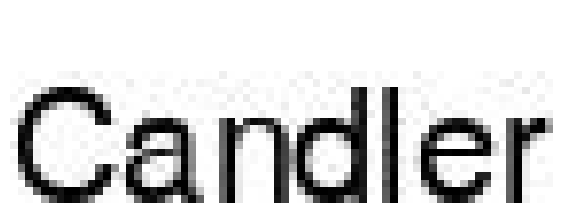

Generated text: Crvener


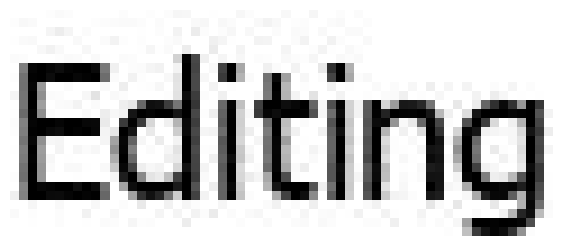

Generated text: Energy


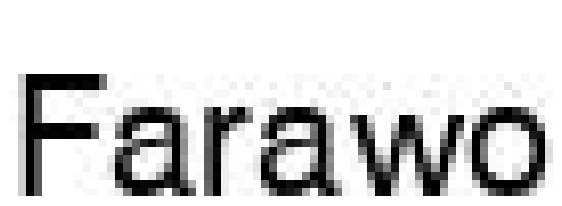

Generated text: Farawo


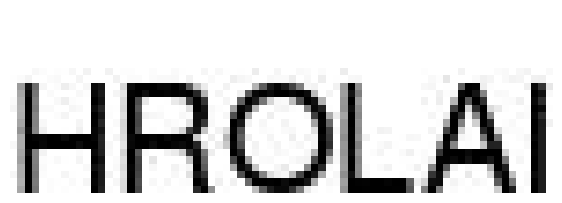

Generated text: APIVAL


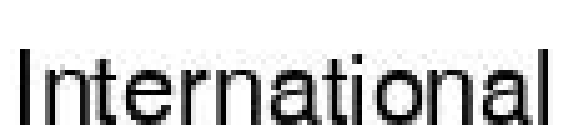

Generated text: International


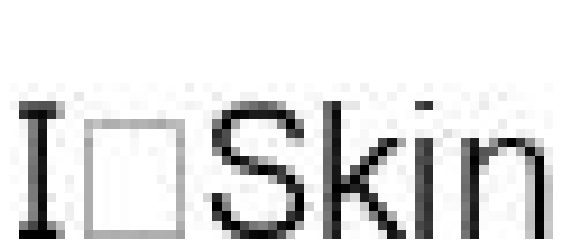

Generated text: 15M


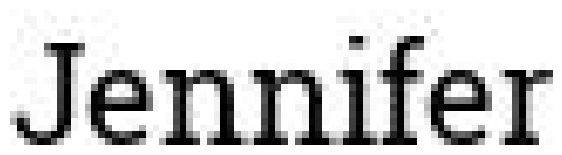

Generated text: Jennifer


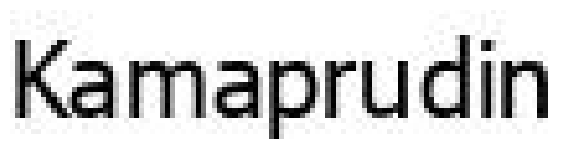

Generated text: Kimpohn


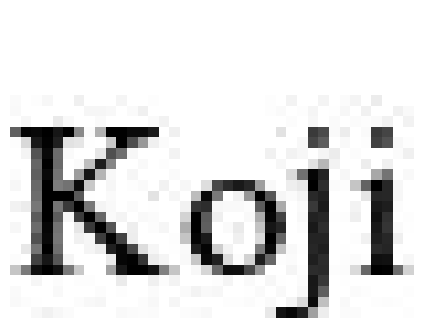

Generated text: K).


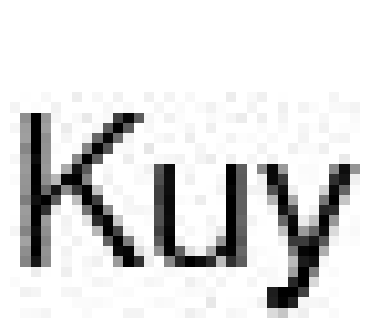

Generated text: Kuy


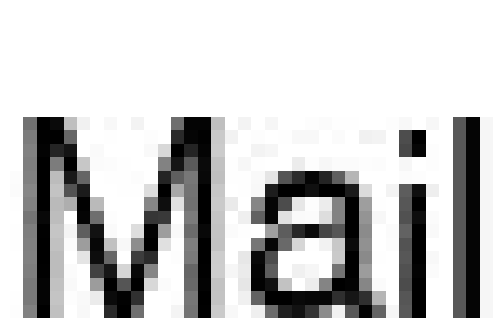

Generated text: Mark


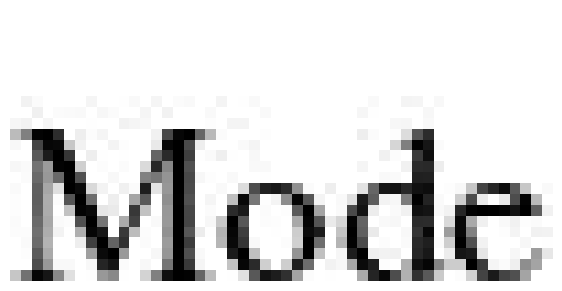

Generated text: Mate


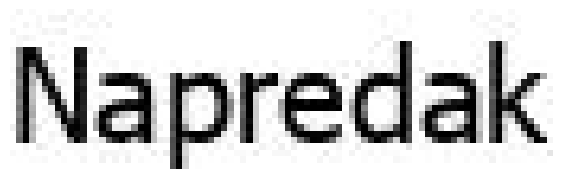

Generated text: Movement


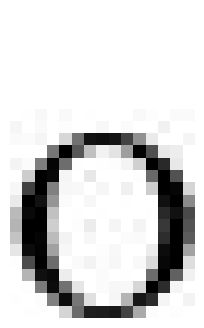

Generated text: O


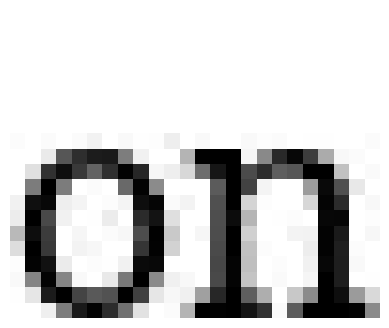

Generated text: on


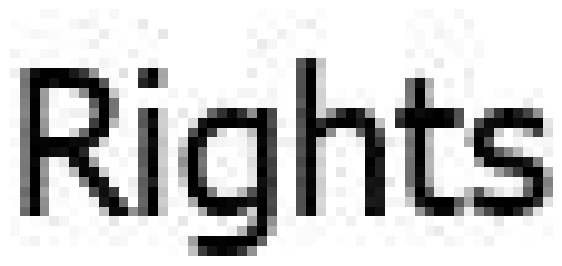

Generated text: Rights


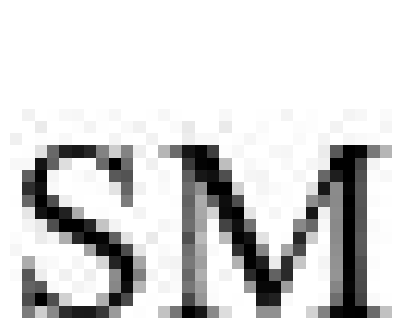

Generated text: SUV


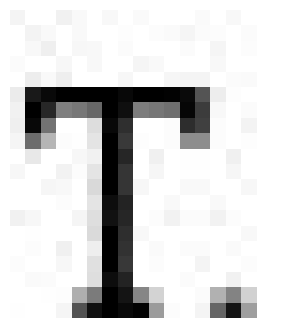

Generated text: T.


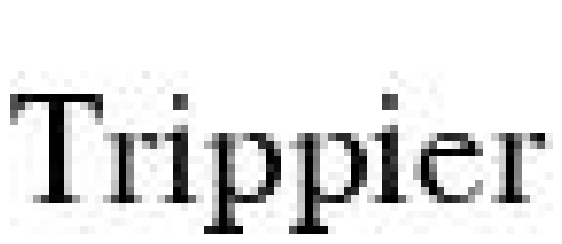

Generated text: Trippier


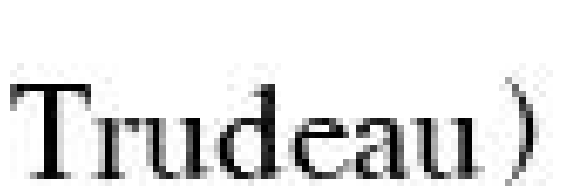

Generated text: Torrance)


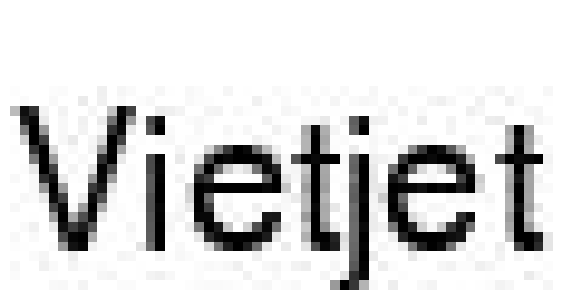

Generated text: Vietjet


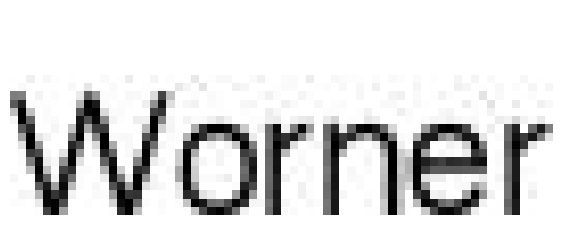

Generated text: Watson


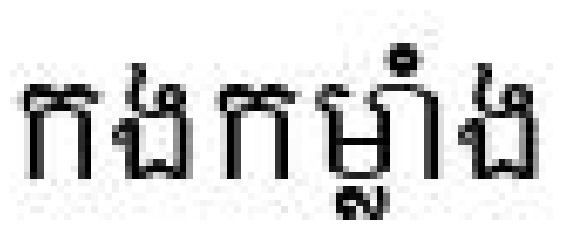

Generated text: កងកម្លាំង


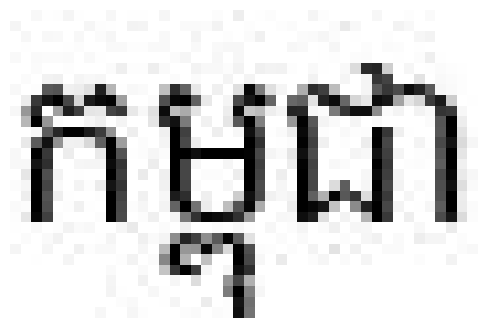

Generated text: កម្ពុជា


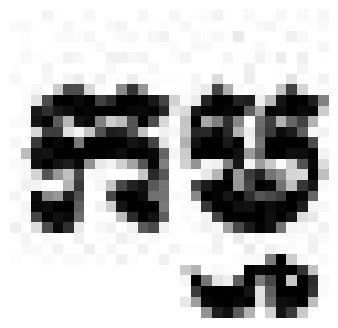

Generated text: ក្ម្ម


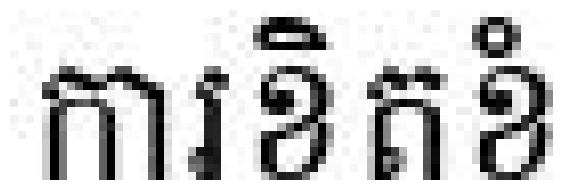

Generated text: ការខិតខំ


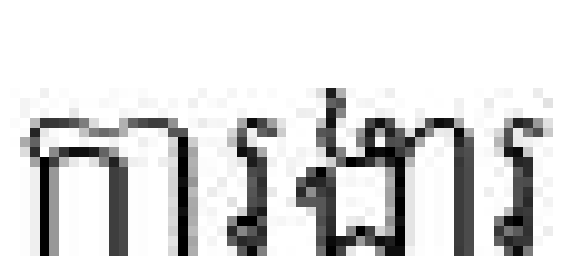

Generated text: ការងារ


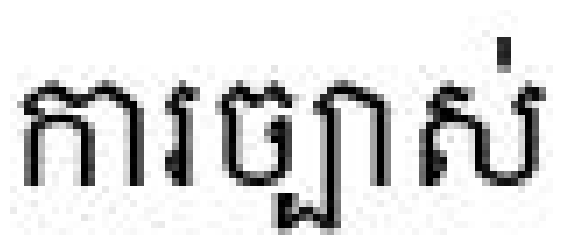

Generated text: ការច្បាស់


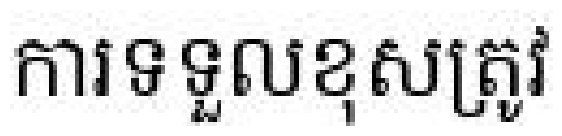

Generated text: ការទទួលបានត្រូវ


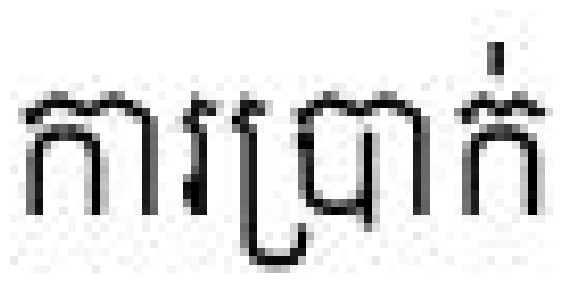

Generated text: ការប្រាក់


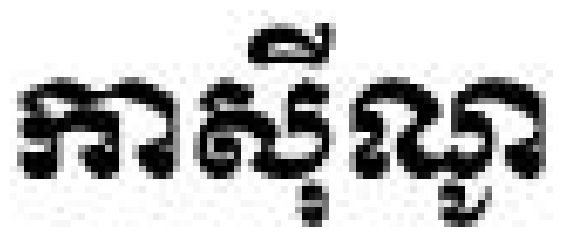

Generated text: កាស៊ីណូ


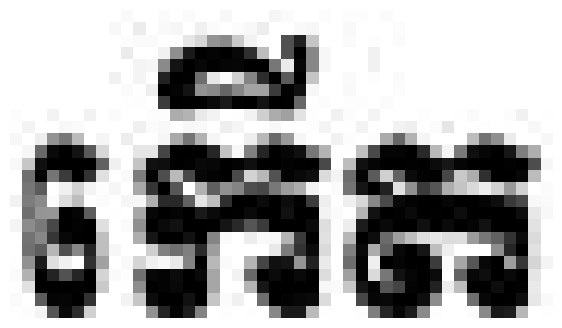

Generated text: កេីត


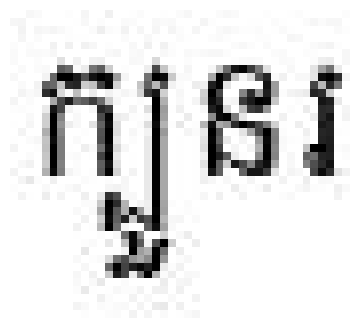

Generated text: ត្បូងនរ


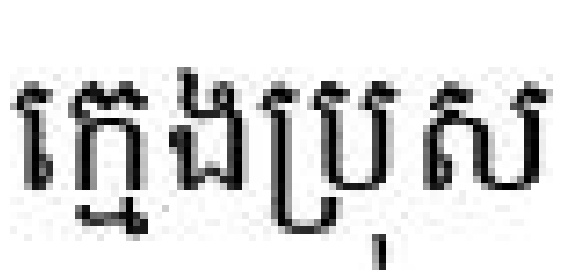

Generated text: ក្មេងប្រុស


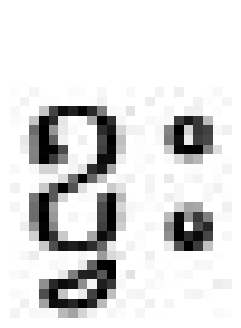

Generated text: ខ្វះ


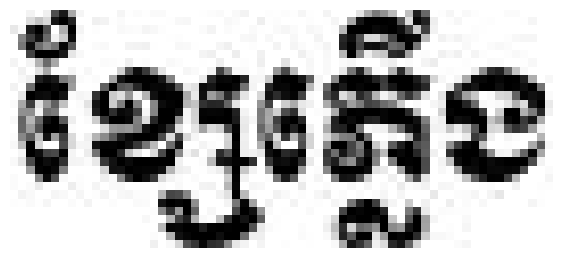

Generated text: ខ្សែភ្លើង


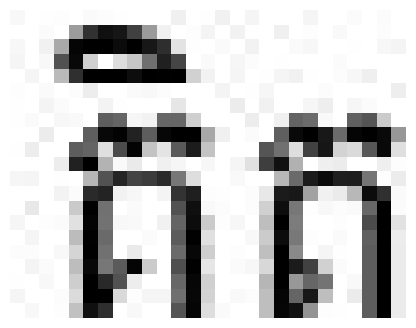

Generated text: គិត


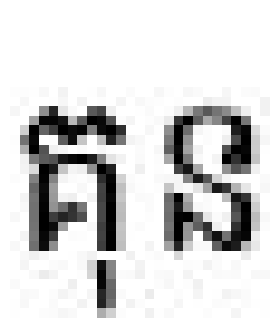

Generated text: គុន


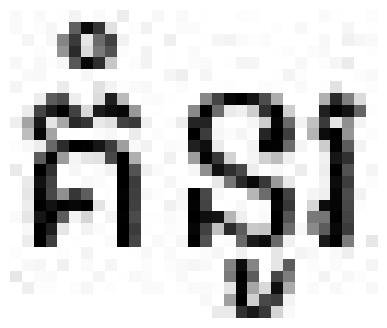

Generated text: គំនូរ


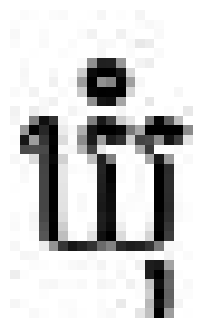

Generated text: ឃុំ


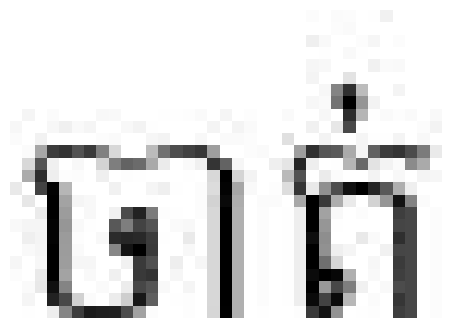

Generated text: ចាត់


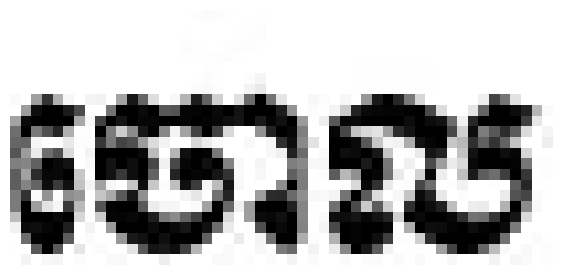

Generated text: ចោល


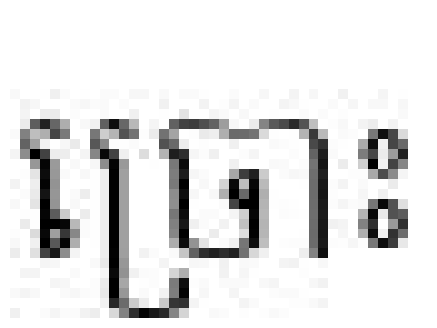

Generated text: ច្រោះ


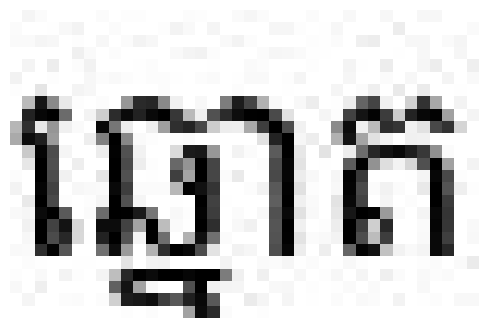

Generated text: ឆ្ោត


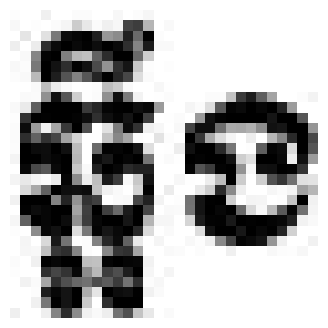

Generated text: ឆ្អឹង


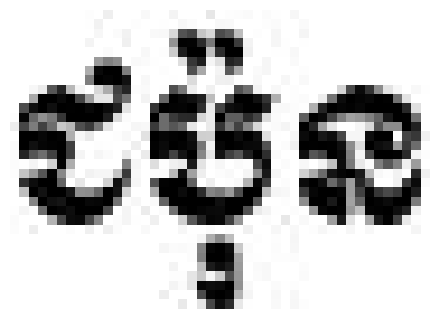

Generated text: ជប៉ុន


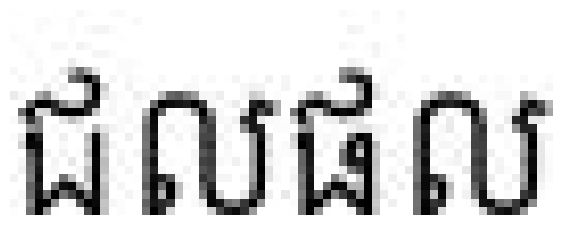

Generated text: ជលជលល


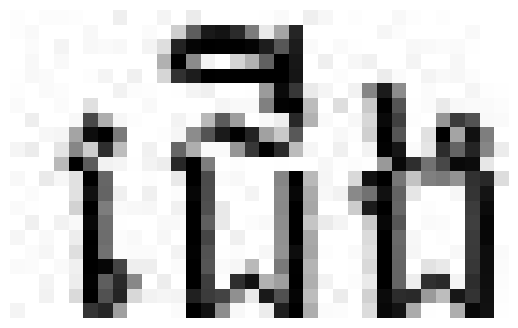

Generated text: ជើង


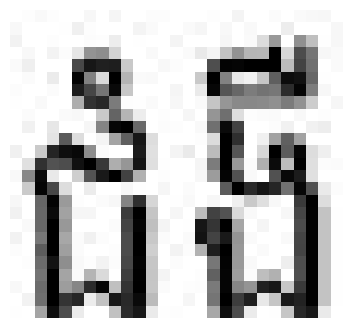

Generated text: ជំងឺ


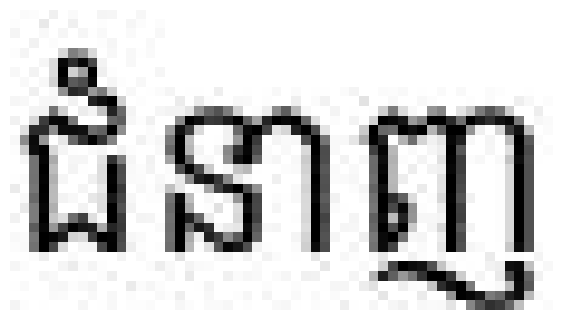

Generated text: ជំនាញ


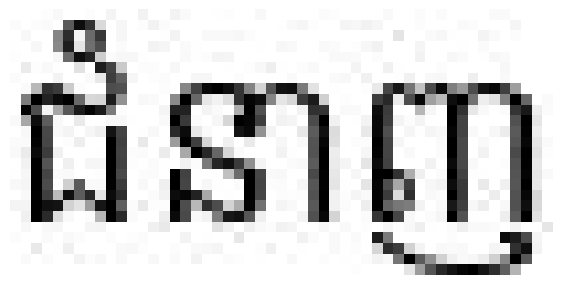

Generated text: ជំនាញ


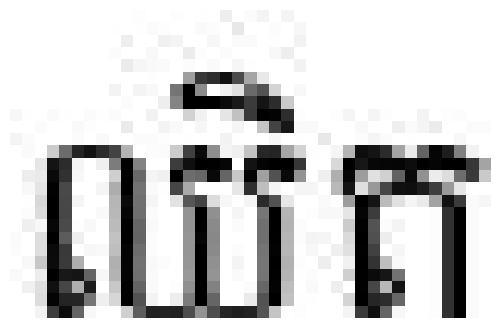

Generated text: ឈិត


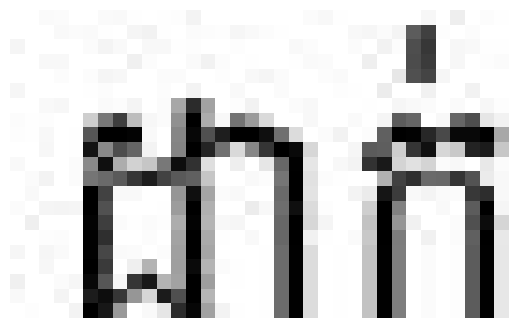

Generated text: ដាក់


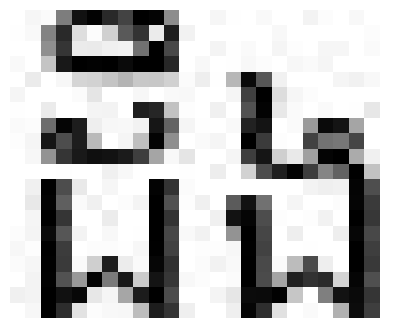

Generated text: ដឹង


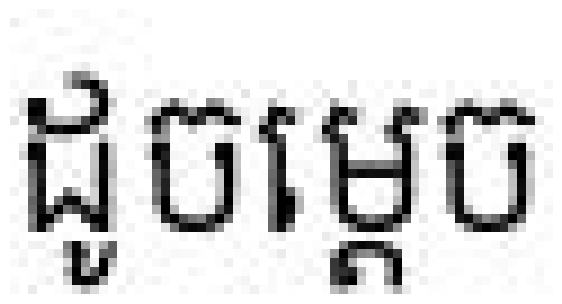

Generated text: ដូចគ្នា


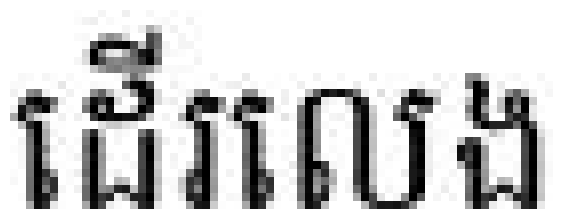

Generated text: ជើងលេង


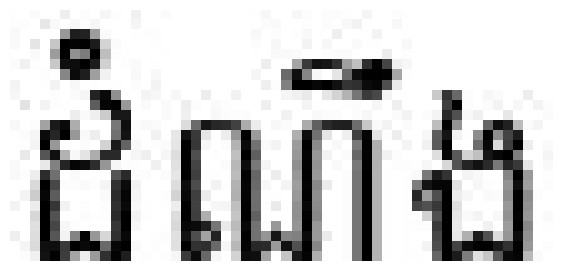

Generated text: ដំណឹង


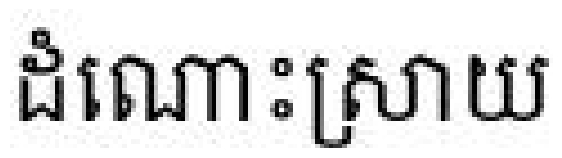

Generated text: ដំណោះស្រាយ


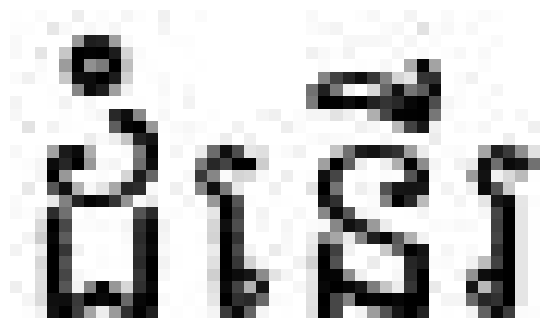

Generated text: ដំនើរ


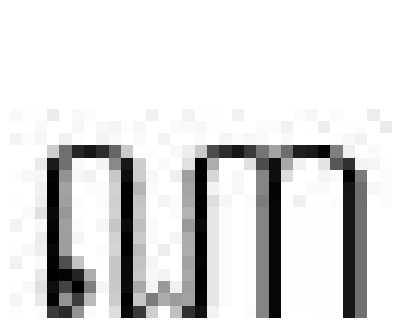

Generated text: ណា


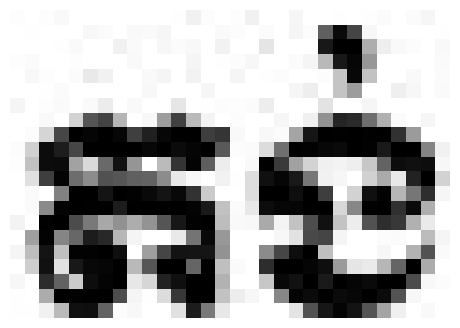

Generated text: តង់


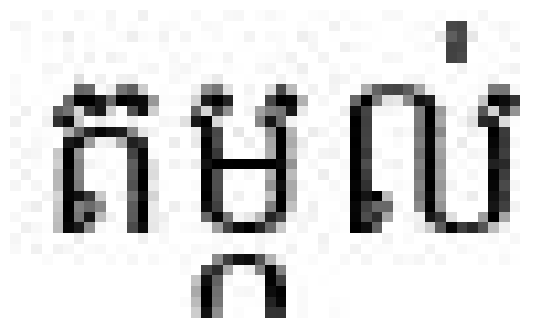

Generated text: តម្កល់


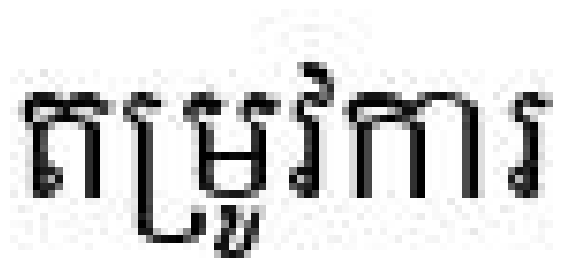

Generated text: តម្រូវការ


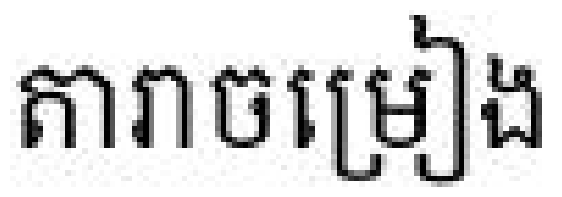

Generated text: ការចម្រៀង


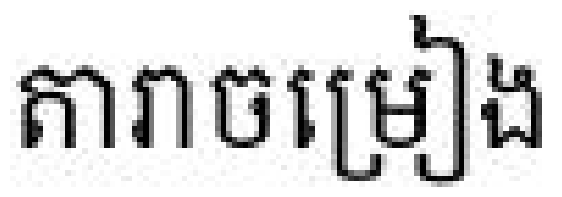

Generated text: ការចម្រៀង


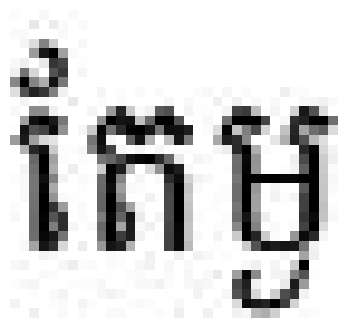

Generated text: កែម្ង


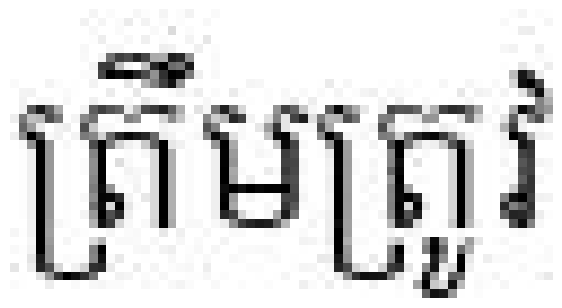

Generated text: ត្រឹមត្រូវ


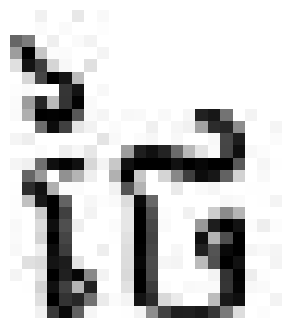

Generated text: ថៃ


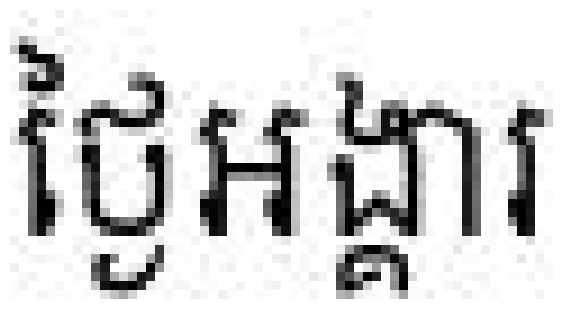

Generated text: ថ្ងៃអង្គារ


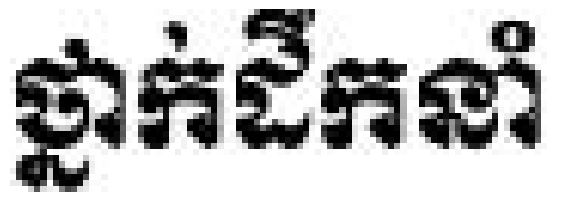

Generated text: ថ្នាក់ដឹកនាំ


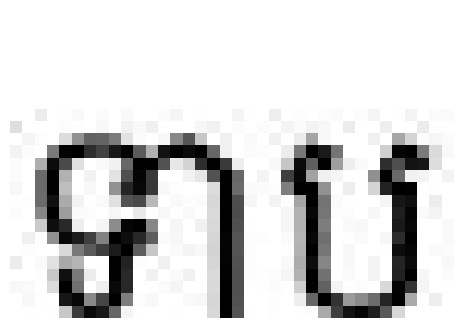

Generated text: ទាប


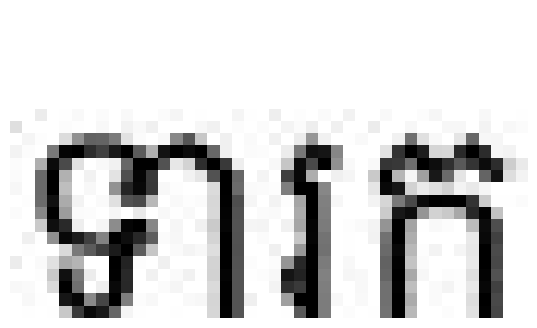

Generated text: ទារក


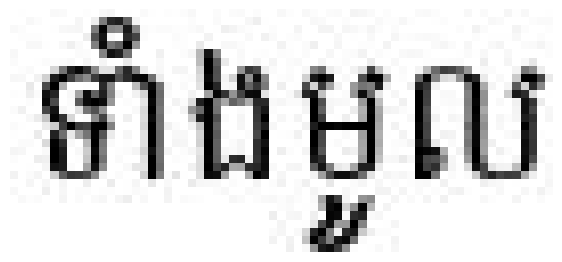

Generated text: ទាំងមូល


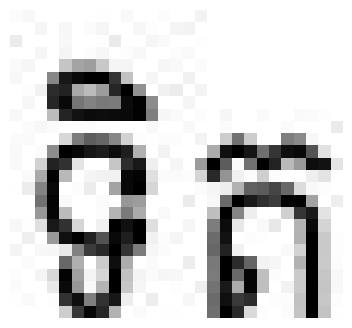

Generated text: ពិត


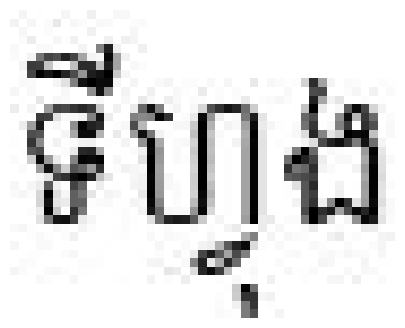

Generated text: ទីហ្វុង


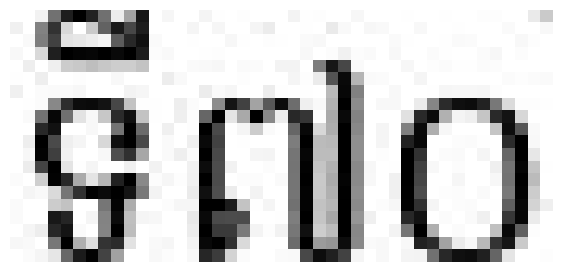

Generated text: ទី៧០


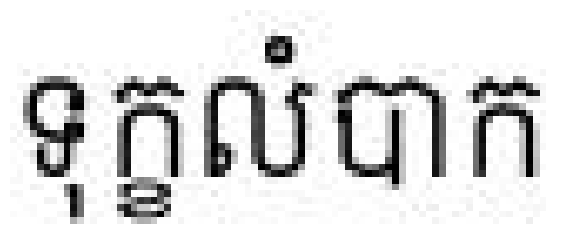

Generated text: ទុក្ខលំបាក


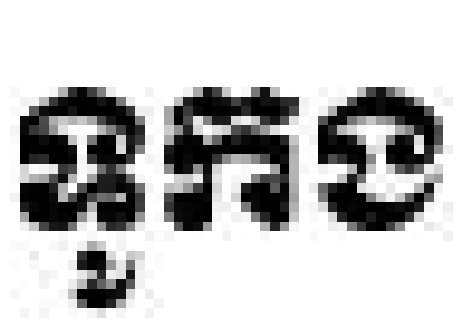

Generated text: ទូកង


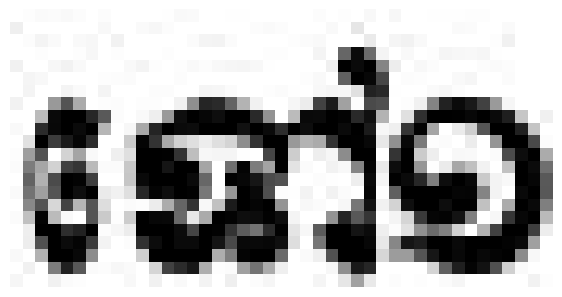

Generated text: ទៅ១


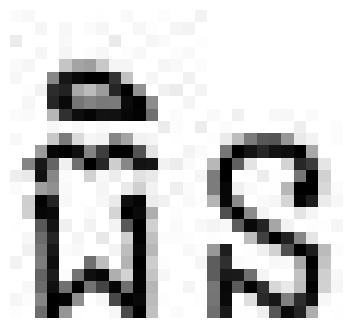

Generated text: ធិន


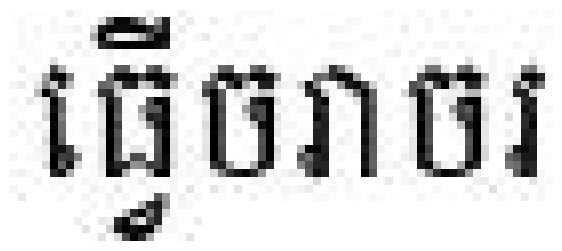

Generated text: ធ្វើចចចរ


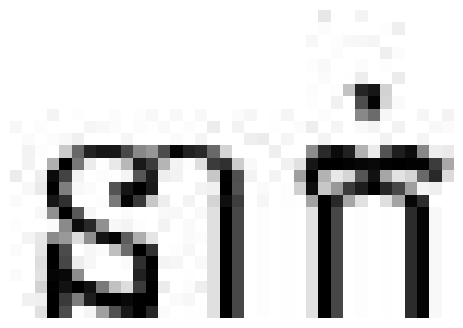

Generated text: នាក់


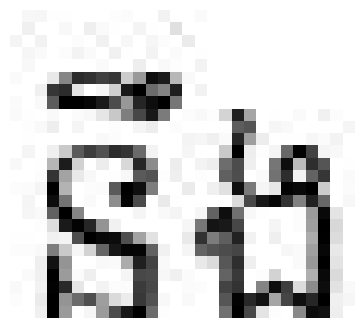

Generated text: នឹង


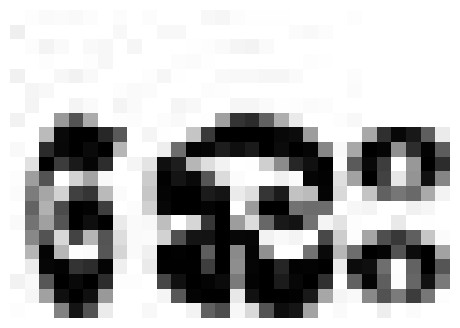

Generated text: នេះ


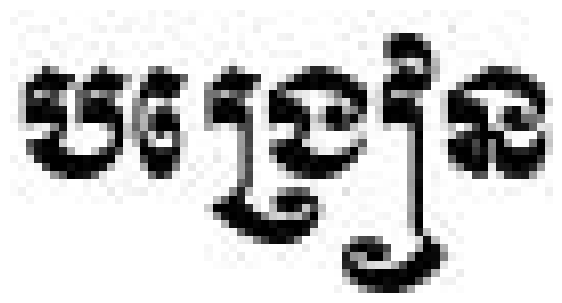

Generated text: បង្រៀន


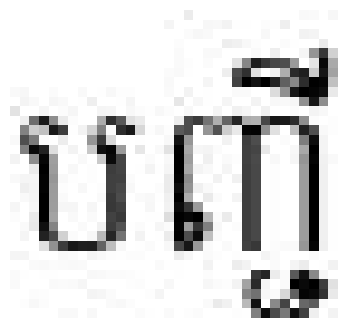

Generated text: បញ្ជី


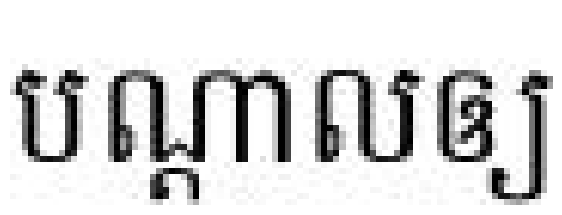

Generated text: បណ្ដាលឲ្យ


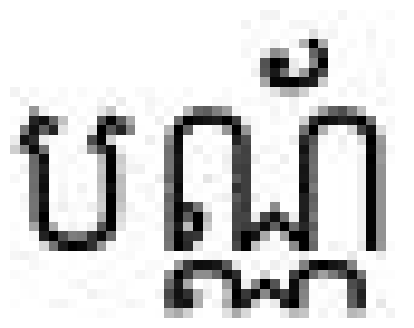

Generated text: បណ្ណ័


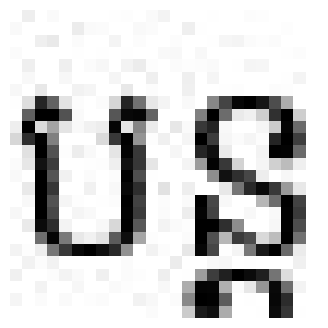

Generated text: បន្ដ


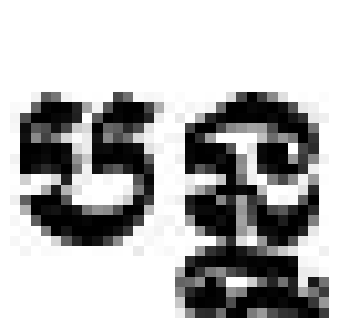

Generated text: បន្ធ


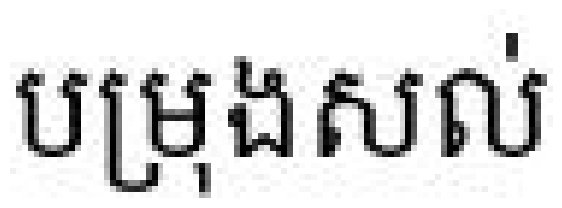

Generated text: ប្រមូលសល់


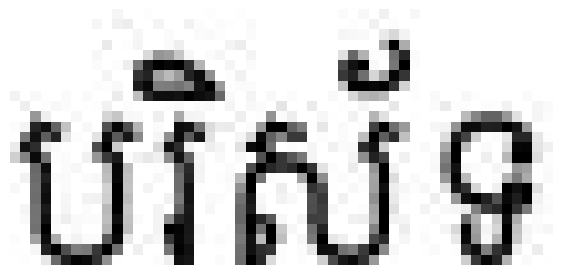

Generated text: បរិស័ទ


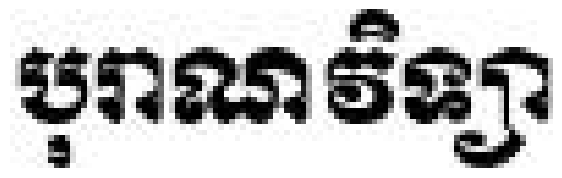

Generated text: បុរាណវិទ្យា


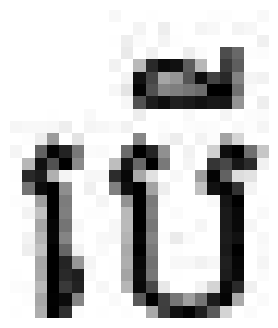

Generated text: បេី


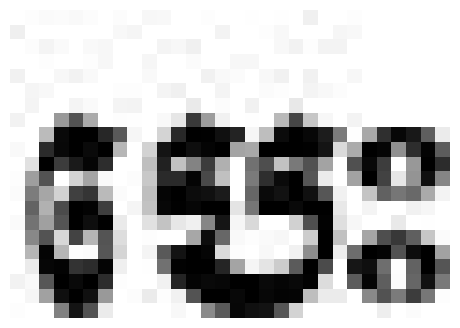

Generated text: បេះ


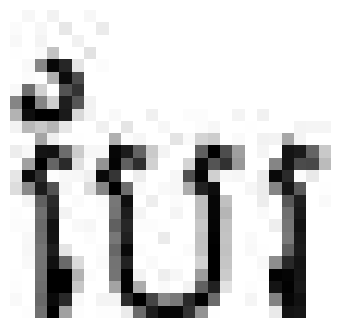

Generated text: បែរ


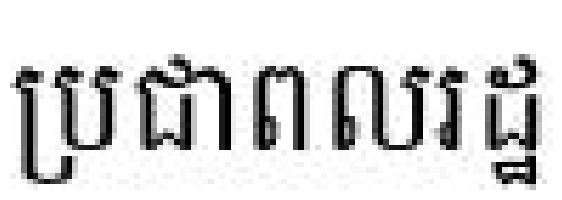

Generated text: ប្រជាពលរដ្ឋ


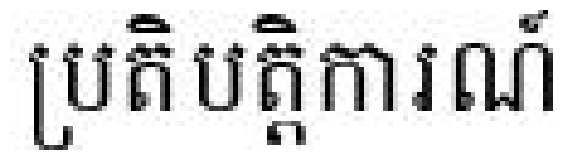

Generated text: ប្រតិបត្តិការ


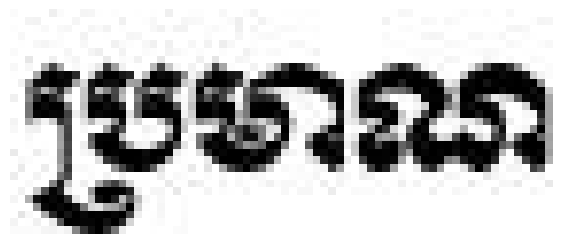

Generated text: ប្រមាណ


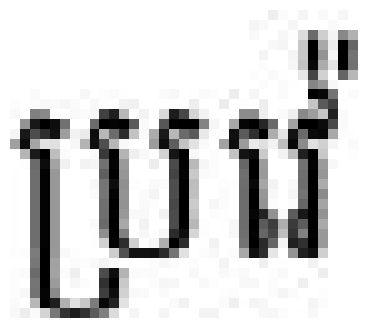

Generated text: ប្រវ៉


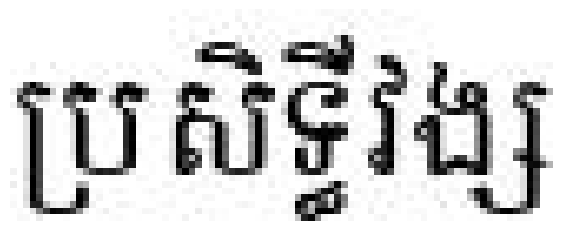

Generated text: ប្រសិទ្ធវង្ស


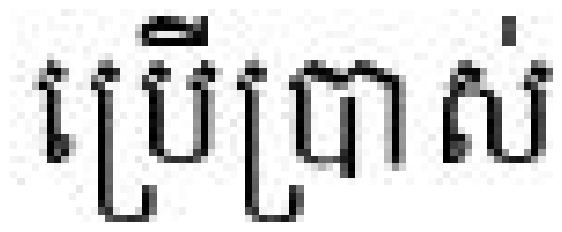

Generated text: ប្រើប្រាស់


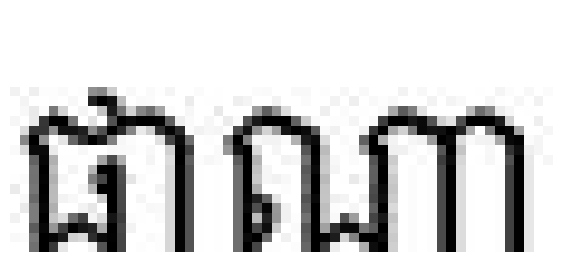

Generated text: ផាណា


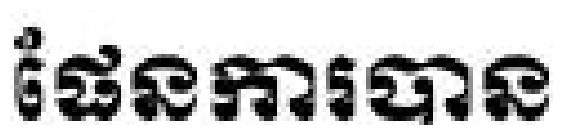

Generated text: ផែនការបាន


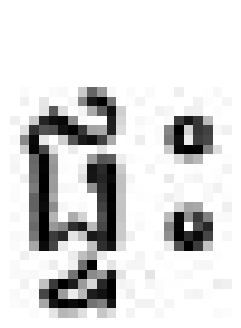

Generated text: ផ្ទះ


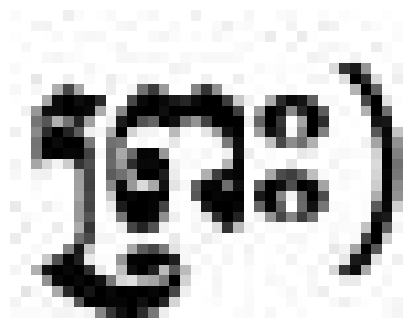

Generated text: ព្រះ)


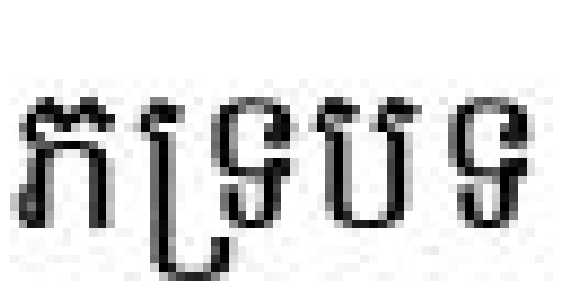

Generated text: ភទ្របទ


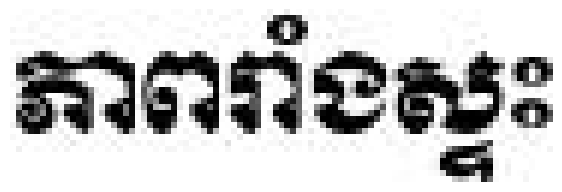

Generated text: ភាពរំាំងស្ទះ


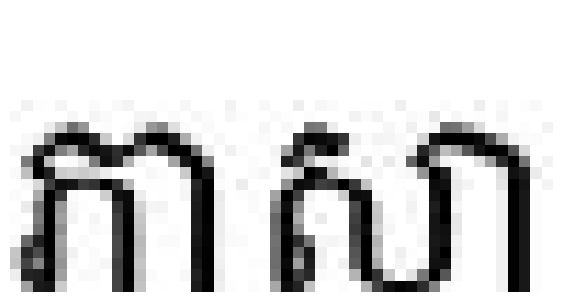

Generated text: ភាសា


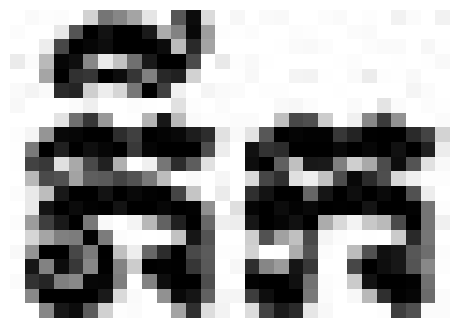

Generated text: ភីក


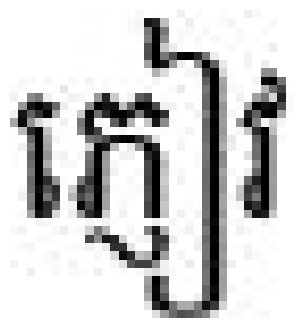

Generated text: ភ្ញៀវ


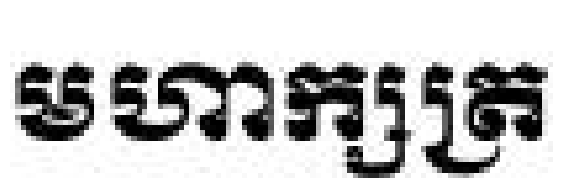

Generated text: មហាក្សត្រ


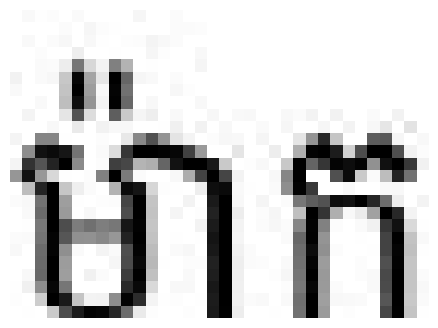

Generated text: ម៉ាក


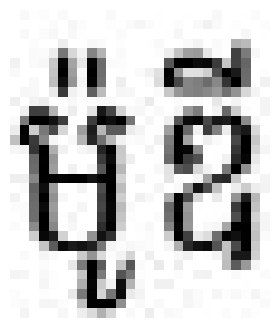

Generated text: ម៉ូឌី


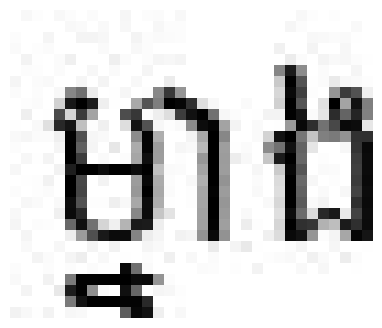

Generated text: ម្នាង


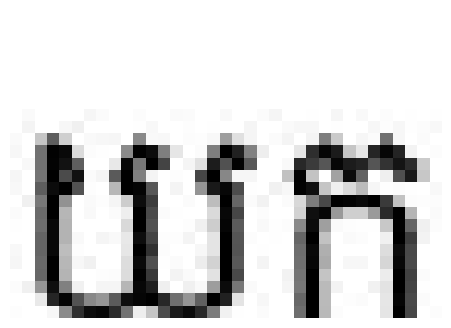

Generated text: យក


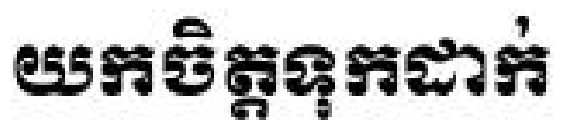

Generated text: យកចិត្តទុកដាក់


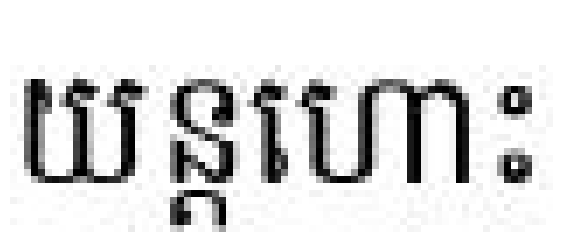

Generated text: យន្តហោះ


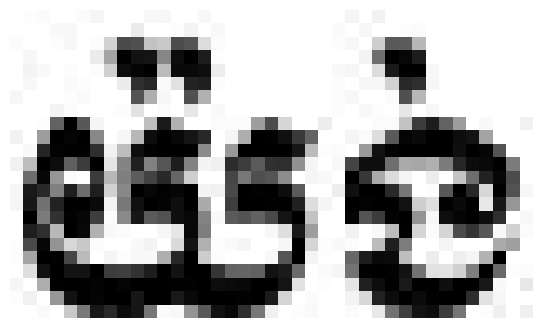

Generated text: យ៉ង់


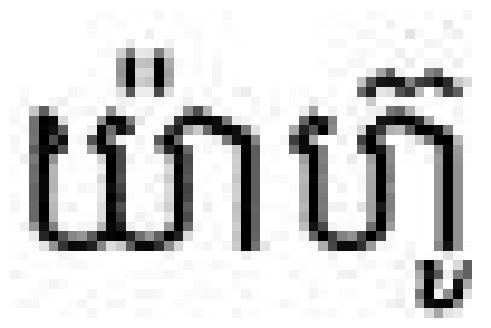

Generated text: យ៉ាហ៊ូ


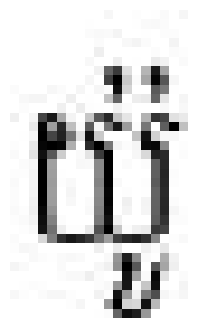

Generated text: យ៉ូ


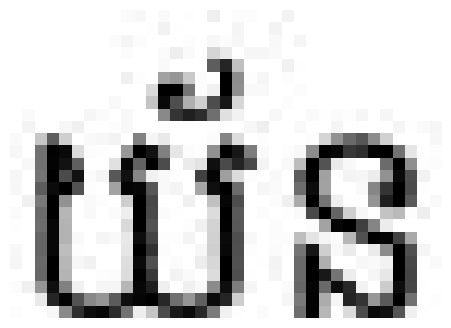

Generated text: យ័ន


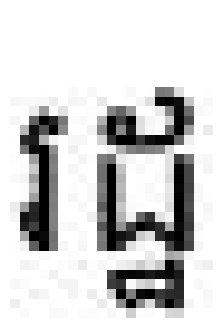

Generated text: រដ្ឋ


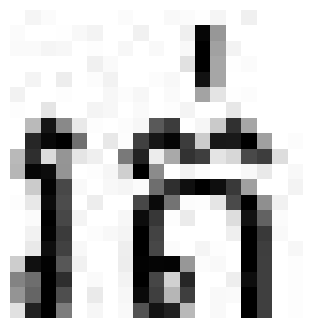

Generated text: រត់


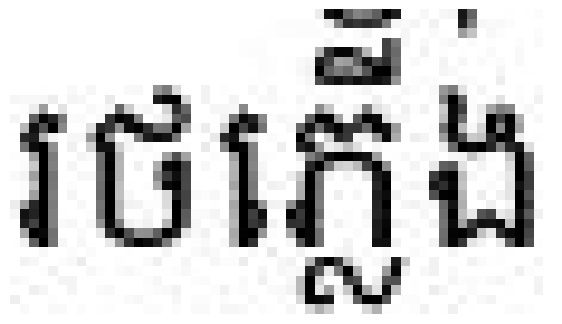

Generated text: រថភ្លើង


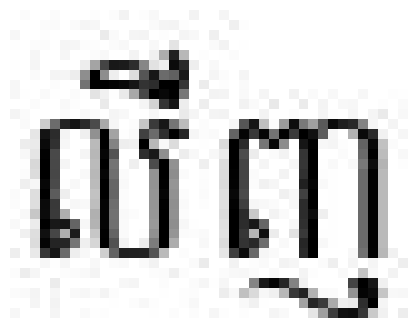

Generated text: លីញ


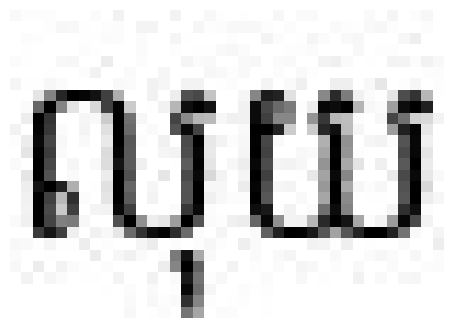

Generated text: លុយ


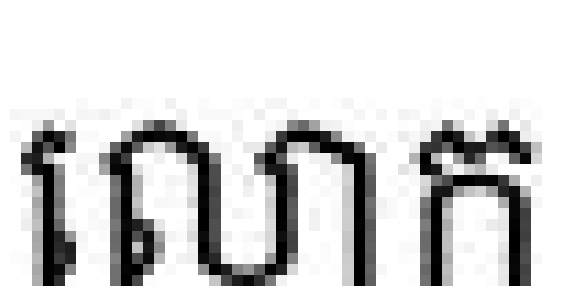

Generated text: លោក


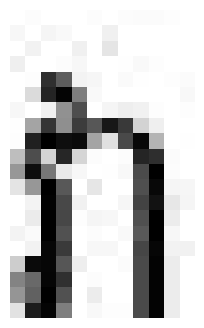

Generated text: វា


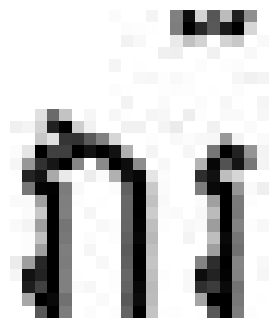

Generated text: វារ


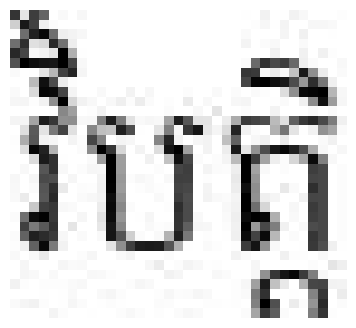

Generated text: វិបត្តិ


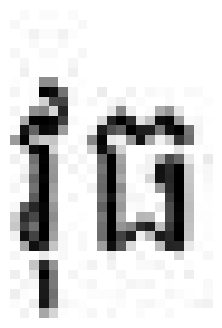

Generated text: វុធ


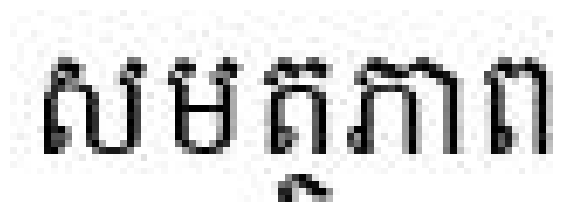

Generated text: សមត្ថភាព


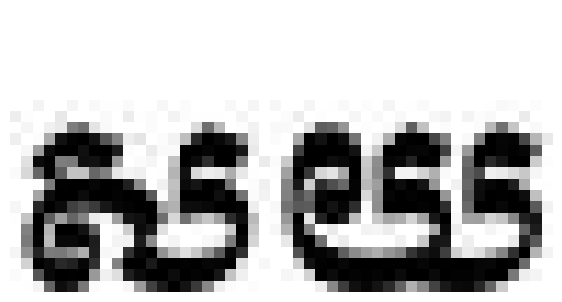

Generated text: សម


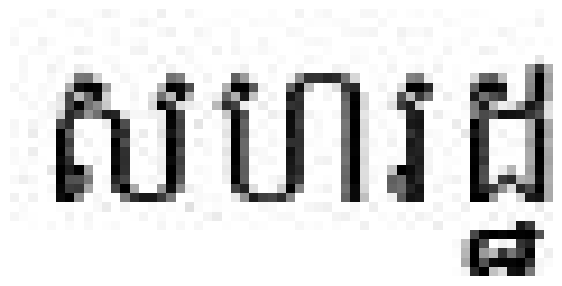

Generated text: សហរដ្ឋ


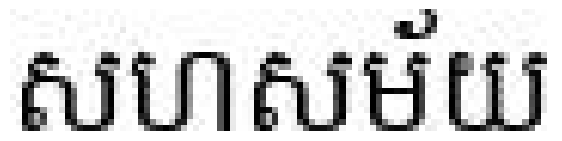

Generated text: សហសម័យ


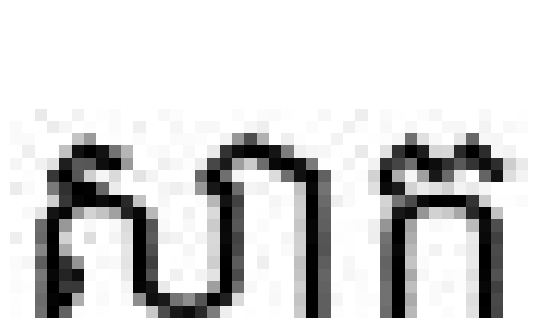

Generated text: សាក


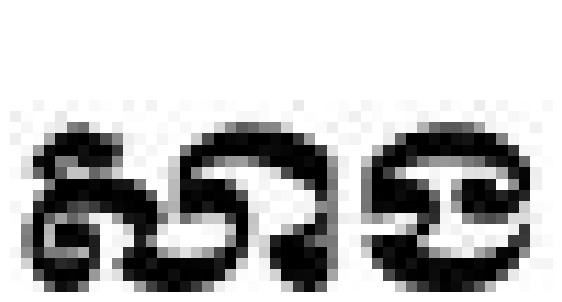

Generated text: សាង


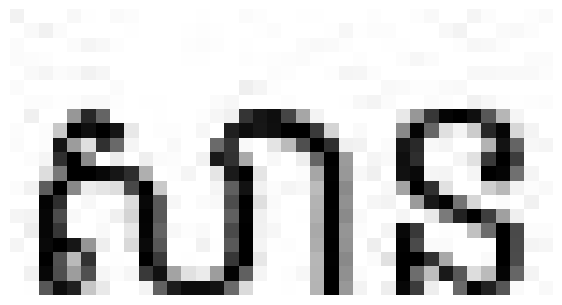

Generated text: សាន


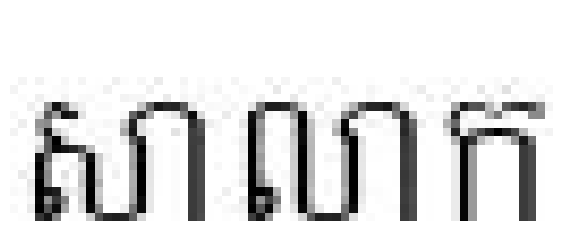

Generated text: សាលាក


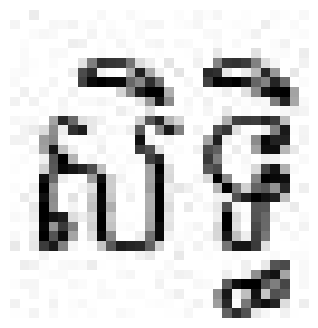

Generated text: សិទ្ធិ


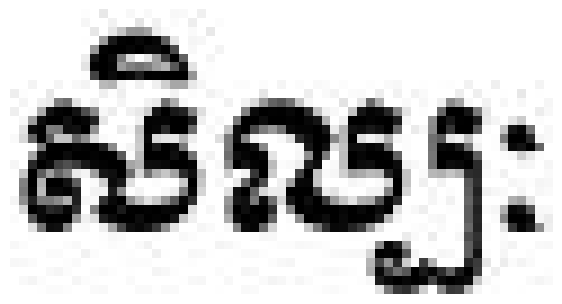

Generated text: សិល្បៈ


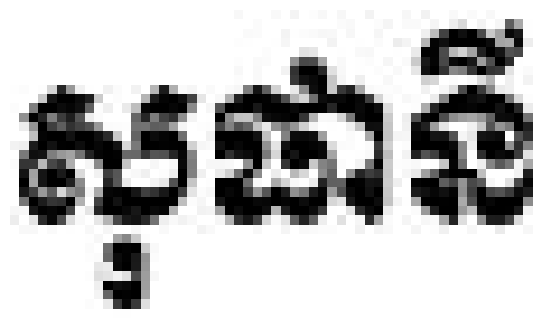

Generated text: សុផានី


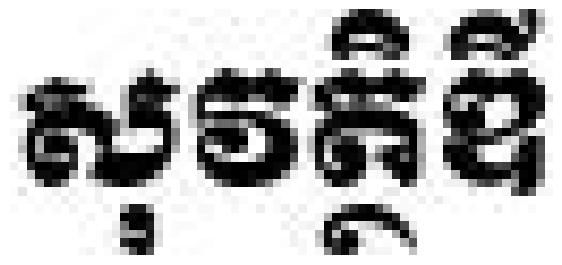

Generated text: សុវត្ថិឌី


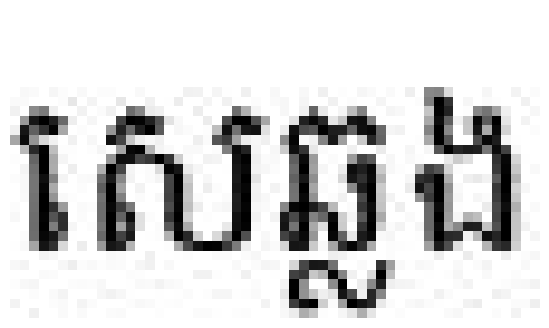

Generated text: សេឆ្លង


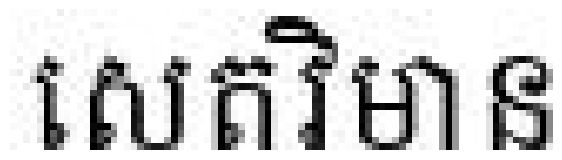

Generated text: សេតវិមាន


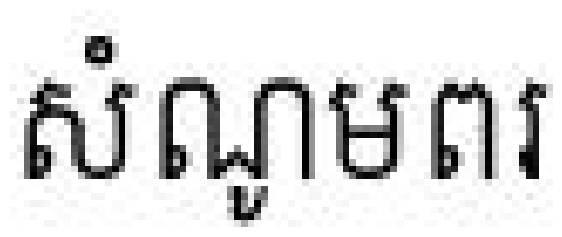

Generated text: សំណូមពរ


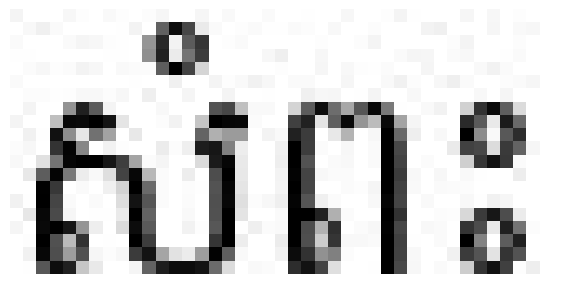

Generated text: សំពះ


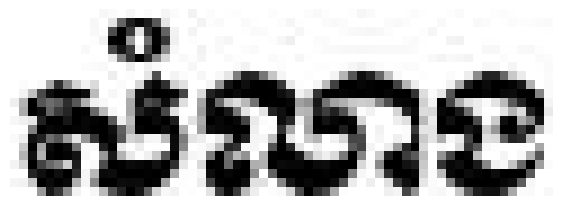

Generated text: សំណង់


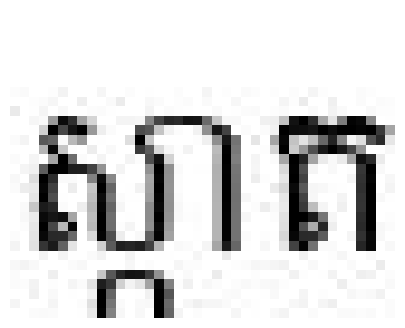

Generated text: ស្តាត


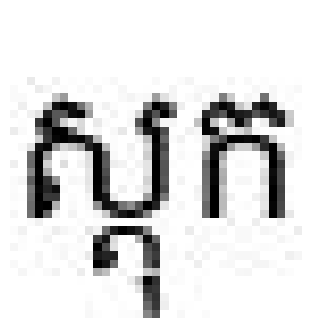

Generated text: ស្តុក


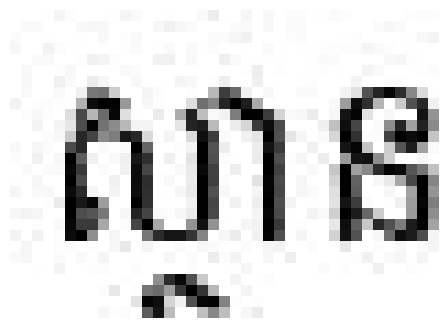

Generated text: ស្ថាន


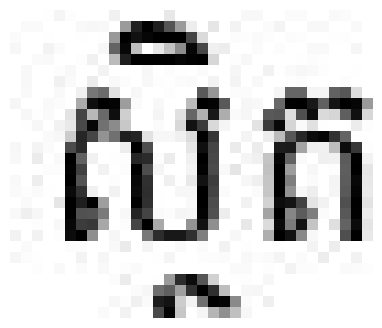

Generated text: ស្ថិត


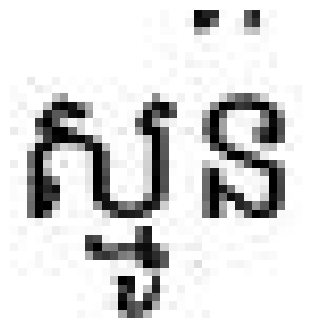

Generated text: ស្មូន


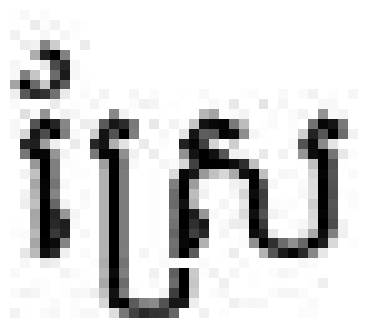

Generated text: ស្រែ


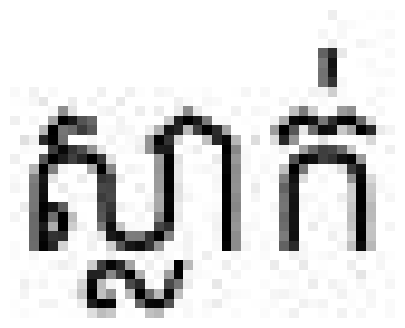

Generated text: ស្លាក់


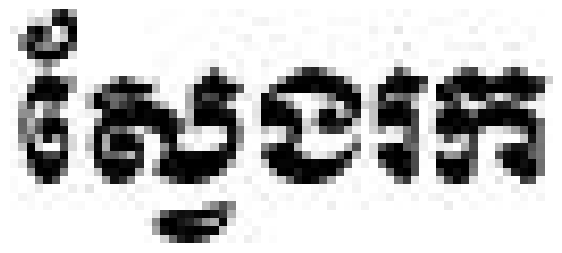

Generated text: ស្វែងរក


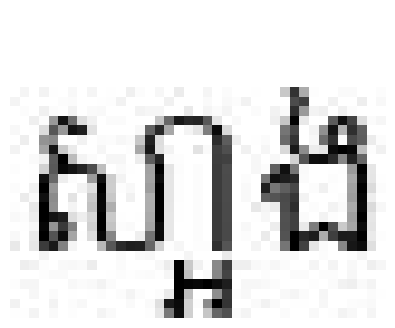

Generated text: ស្អាង


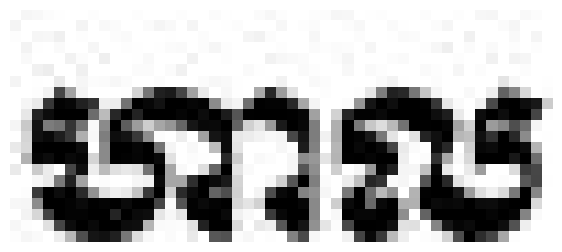

Generated text: ហាល


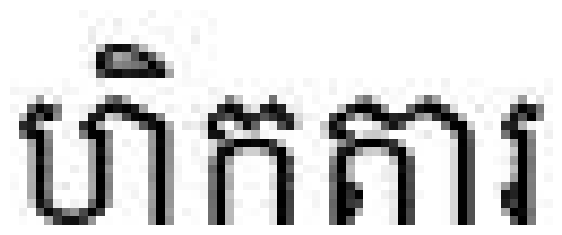

Generated text: ហិកការ


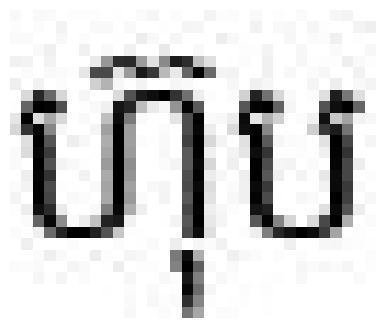

Generated text: ហ៊ុប


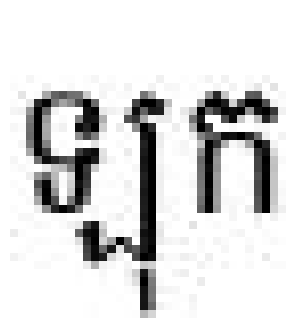

Generated text: ឡុក


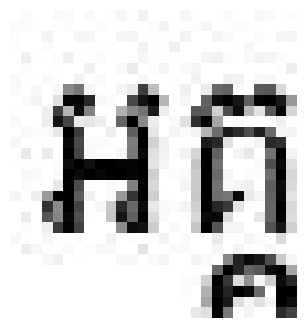

Generated text: អគ្គ


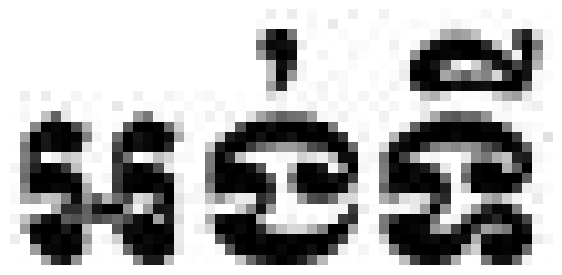

Generated text: អង់ទី


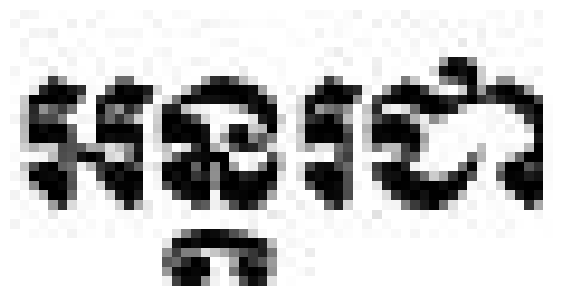

Generated text: អន្តរជា


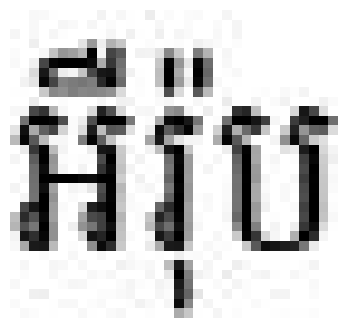

Generated text: អឺរ៉ុប


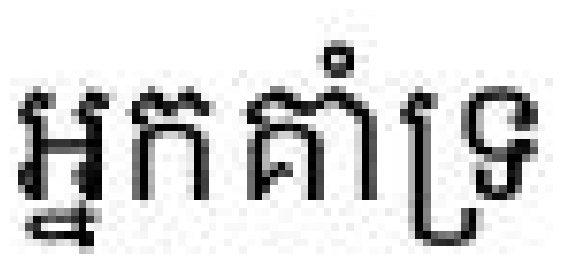

Generated text: អ្នកគាំទ្រ


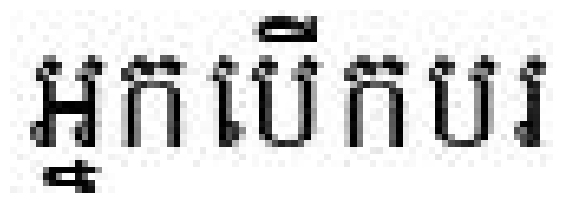

Generated text: អ្នកបើកបរ


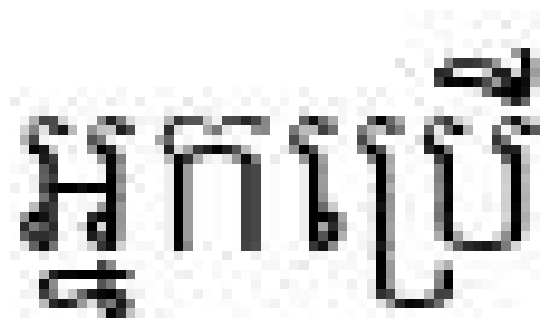

Generated text: អ្នកប្រើ


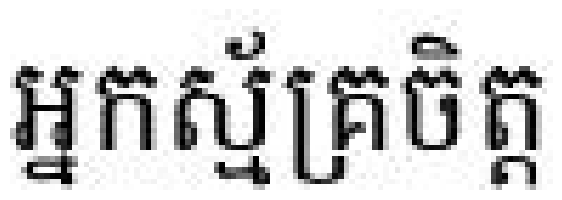

Generated text: អ្នកស្ម័គ្រចិត្


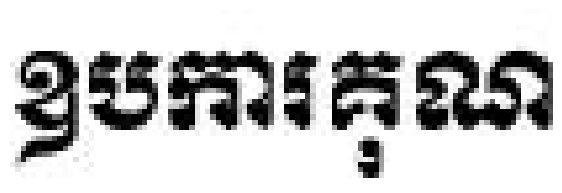

Generated text: ឧបការគុណ


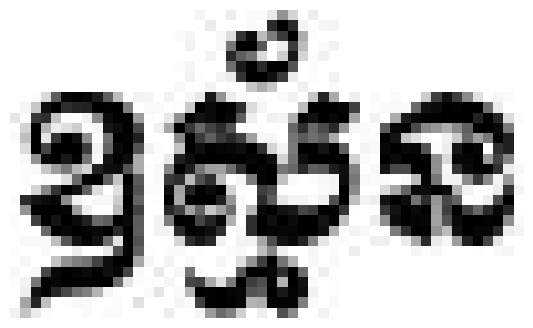

Generated text: ឧស្ម័ន


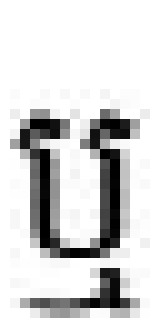

Generated text: ឬ


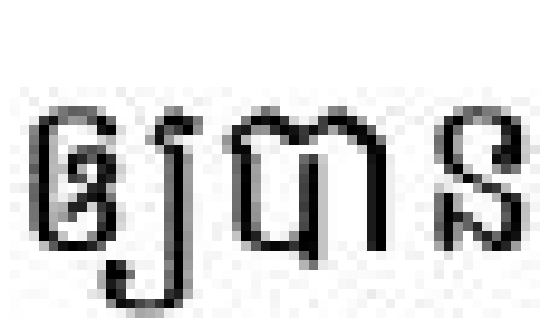

Generated text: ឲ្យបាន


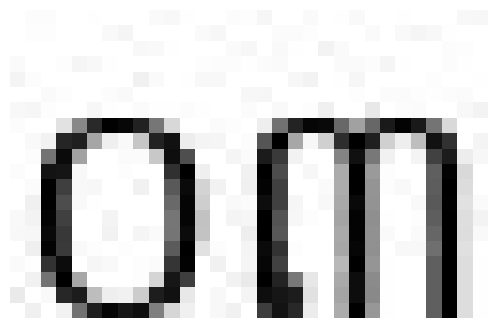

Generated text: ០៣


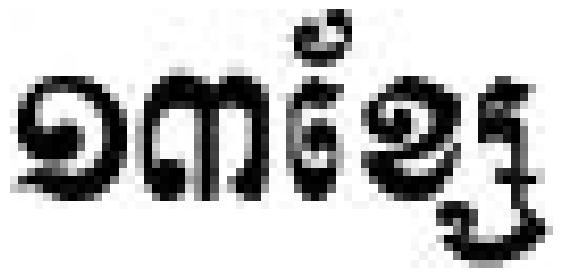

Generated text: ១៣ខ្សែែ


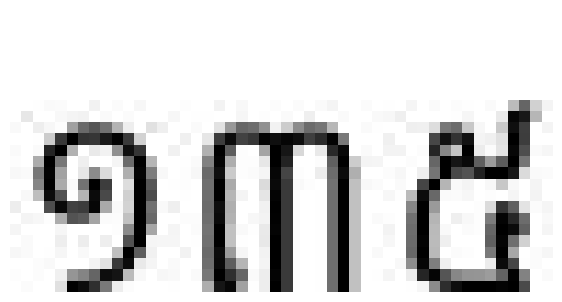

Generated text: ១៣៥


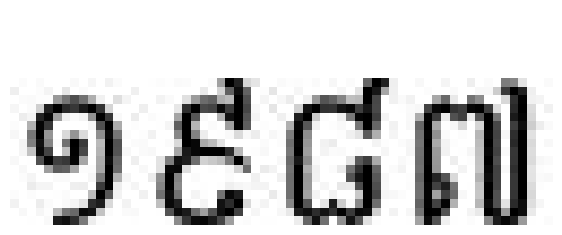

Generated text: ១៩៨៧


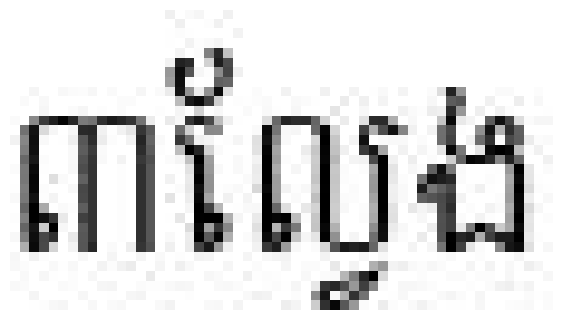

Generated text: ៣លវែង


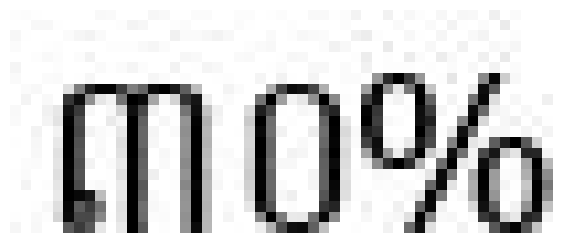

Generated text: ៣១០%


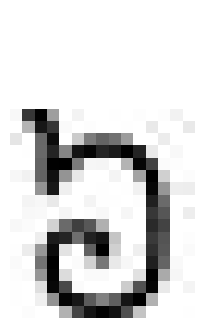

Generated text: ៦


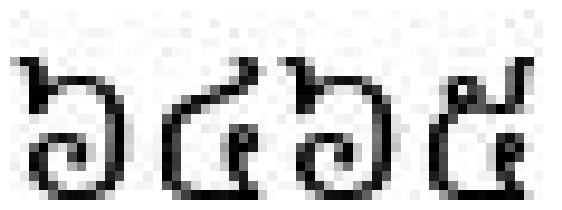

Generated text: ៦៤៦៥


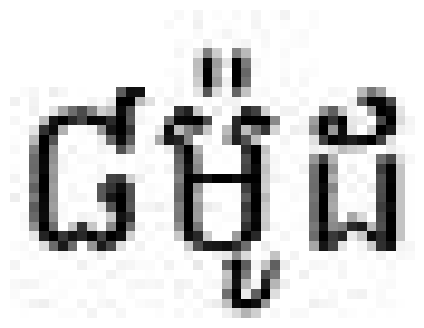

Generated text: ៨ម៉ូដ


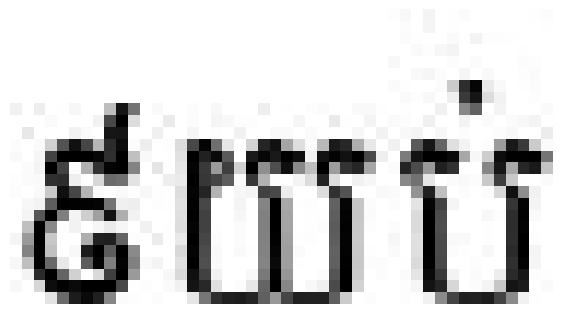

Generated text: ៩យប់


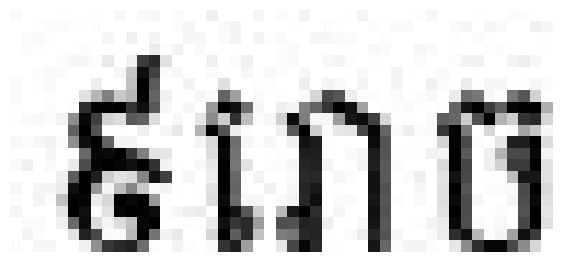

Generated text: ៩រោច


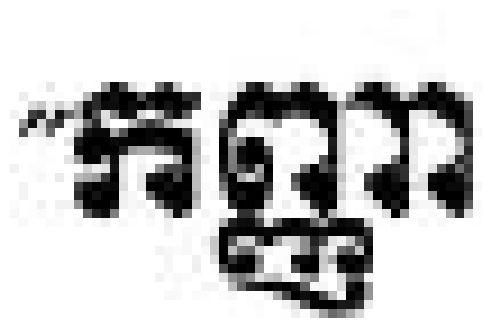

Generated text: កញ្ញ្ញ្ញ


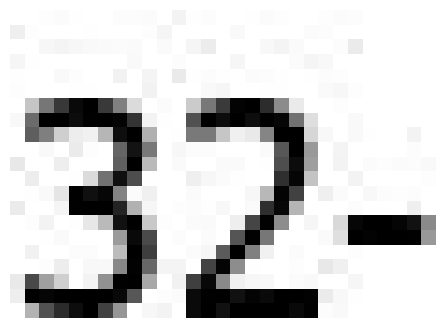

Generated text: 3-1


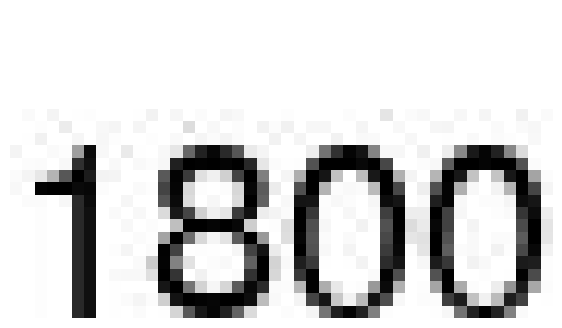

Generated text: 1030


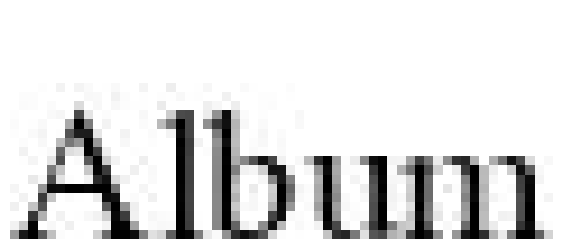

Generated text: Aramា


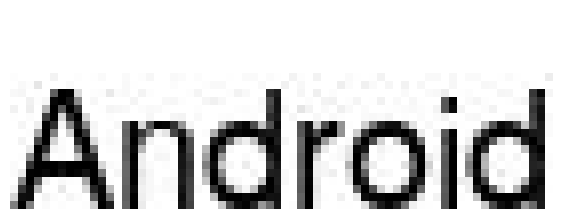

Generated text: Android


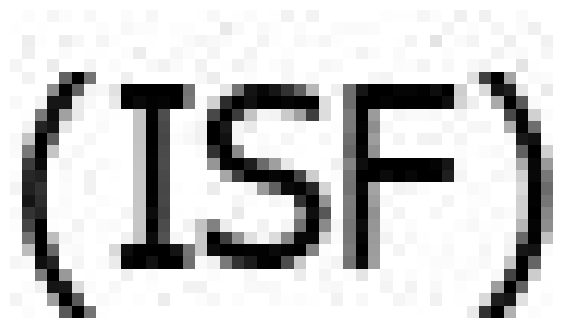

Generated text: (ICE)


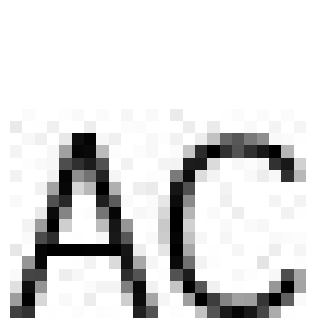

Generated text: AC


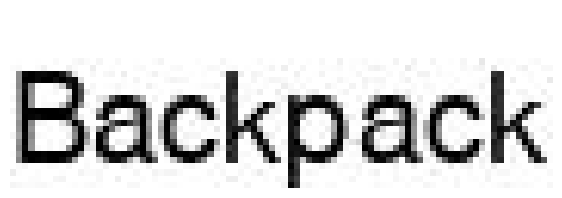

Generated text: Basook


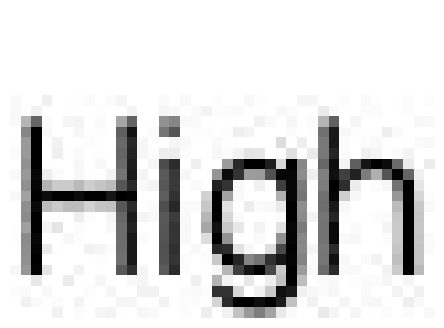

Generated text: High


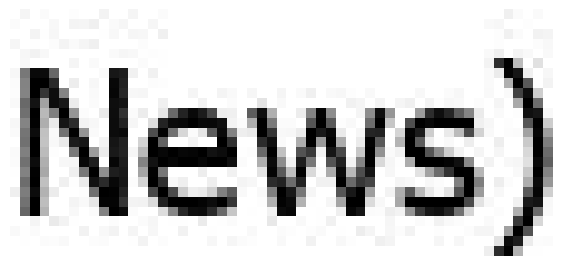

Generated text: Mbas)


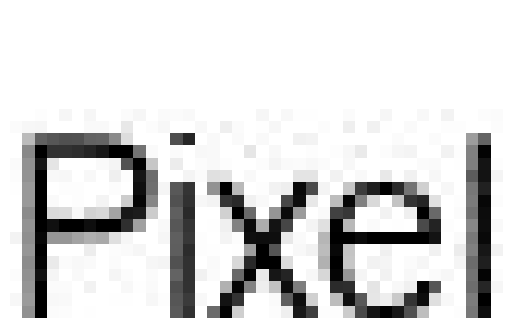

Generated text: Pixel


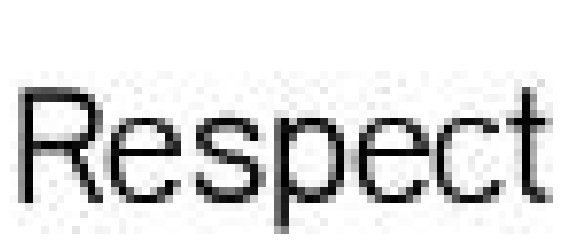

Generated text: Filipinaer


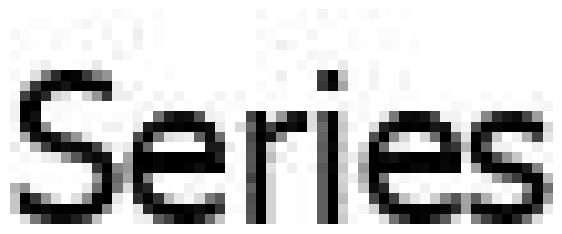

Generated text: Series


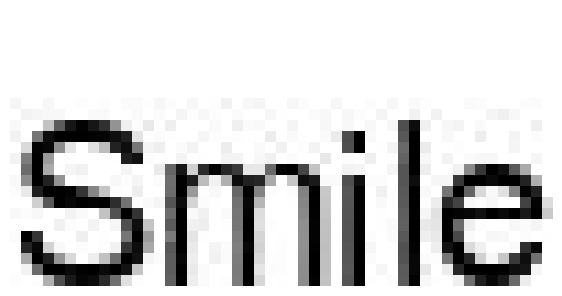

Generated text: Shine


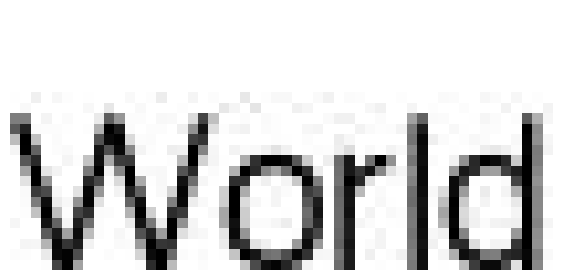

Generated text: World


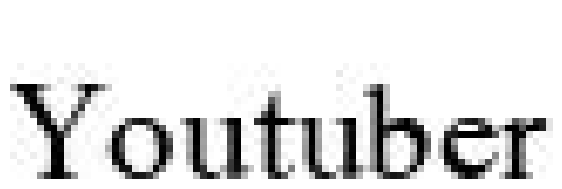

Generated text: Youutree


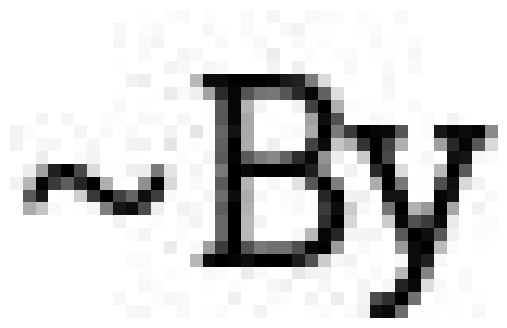

Generated text: ។BA


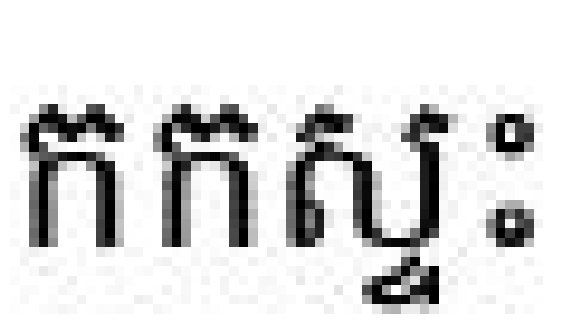

Generated text: កកស្ទះ


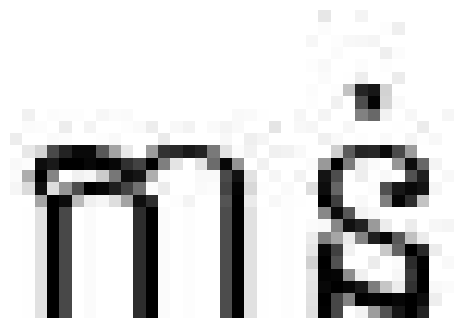

Generated text: កាន់


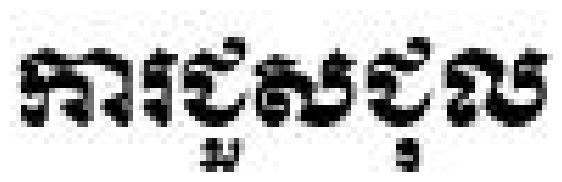

Generated text: ការជួសជុល


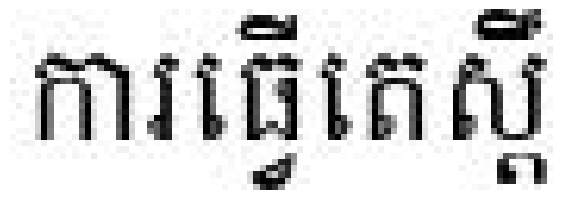

Generated text: ការធ្វើតេស្តិ


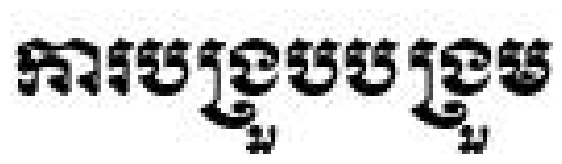

Generated text: ការបុងប្រសម្រួល


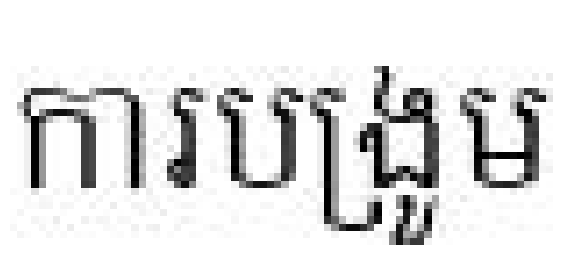

Generated text: ការបង្រួម


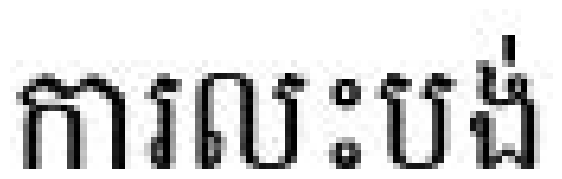

Generated text: ការលបង់


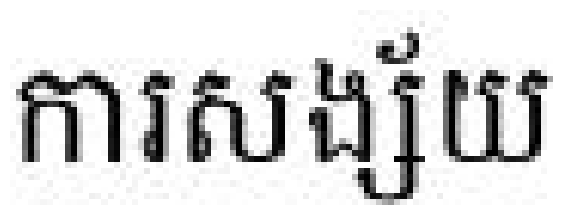

Generated text: ការសង្ង័យ


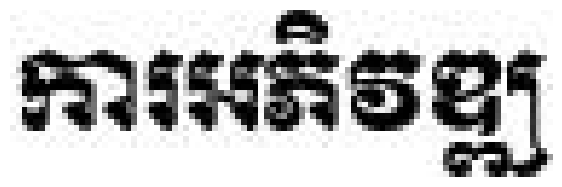

Generated text: ការអភិវឌ្ឍ


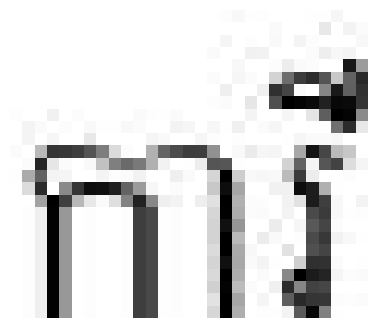

Generated text: ការី


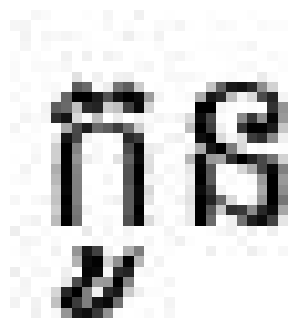

Generated text: កូន


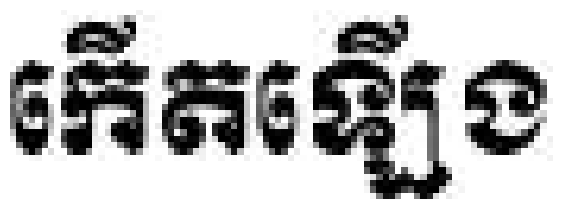

Generated text: កើតឡើង


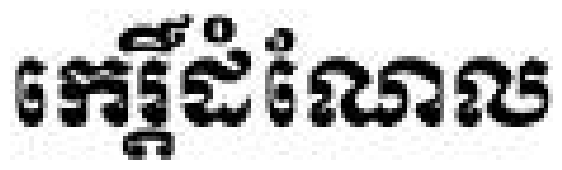

Generated text: កអេដំដំែលល


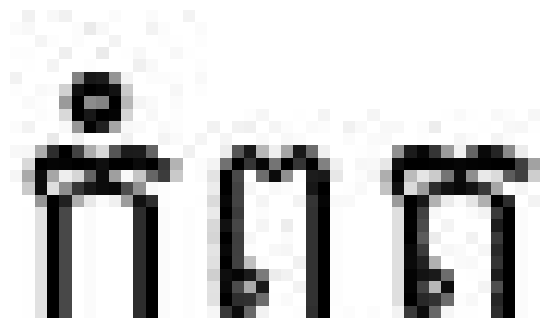

Generated text: កំពត


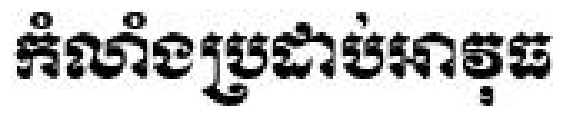

Generated text: កំណលដាប់អអអអអអអអអ


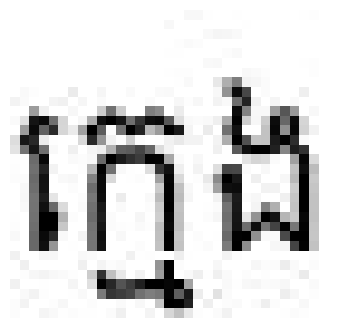

Generated text: ក្មេង


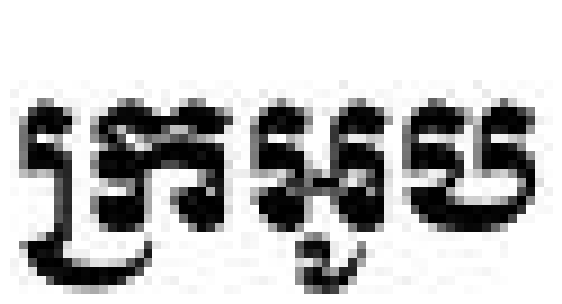

Generated text: ក្រអូប


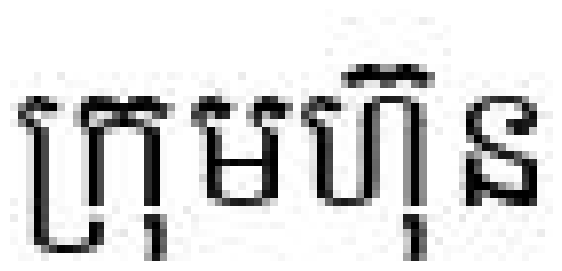

Generated text: ក្រុមហ៊ុន


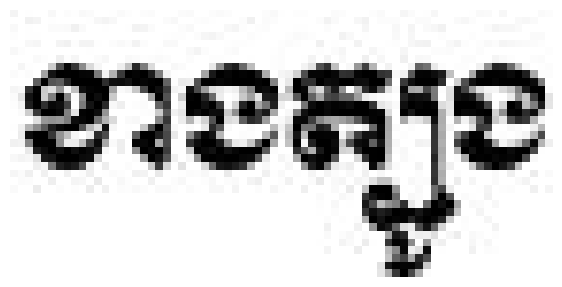

Generated text: ខាងត្បូង


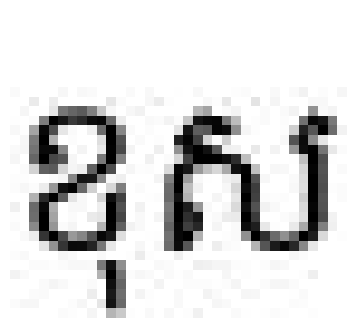

Generated text: ខុស


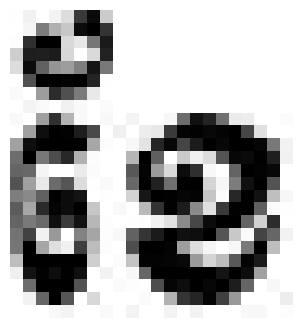

Generated text: ខែ


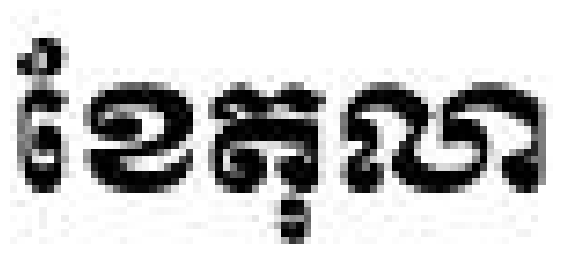

Generated text: ខែតុលា


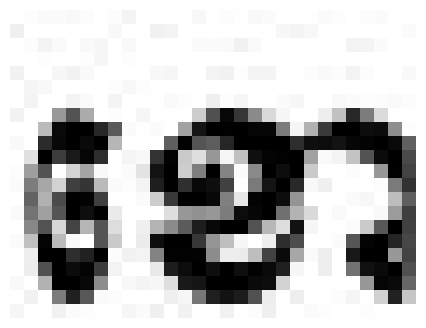

Generated text: ខោ


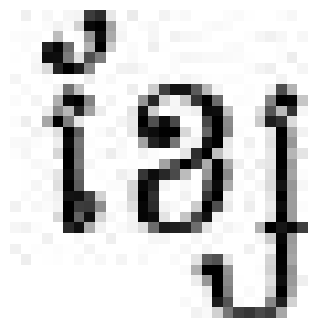

Generated text: ខ្សែ


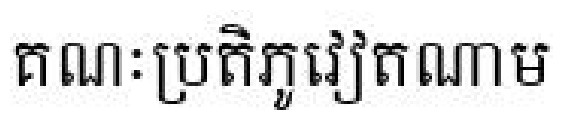

Generated text: គណៈកម្មការកក


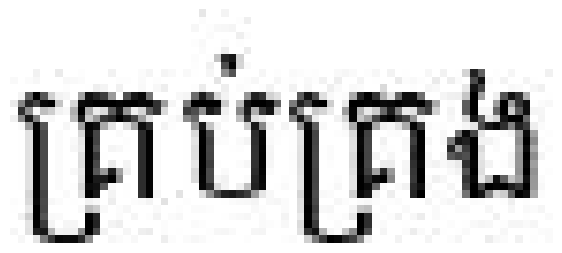

Generated text: គ្រប់គ្រង


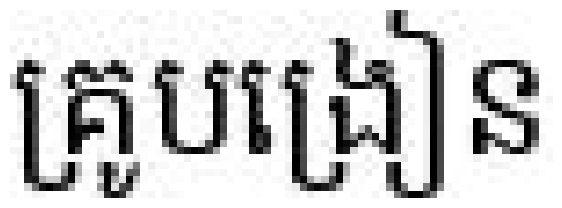

Generated text: គ្រូបង្រៀន


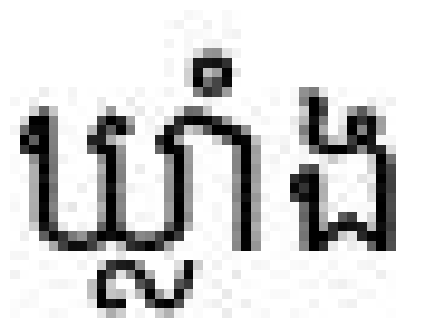

Generated text: ឃ្លាំង


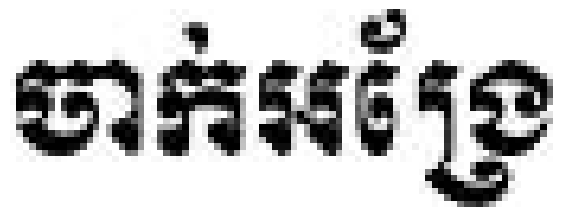

Generated text: ចាក់អង្រែ


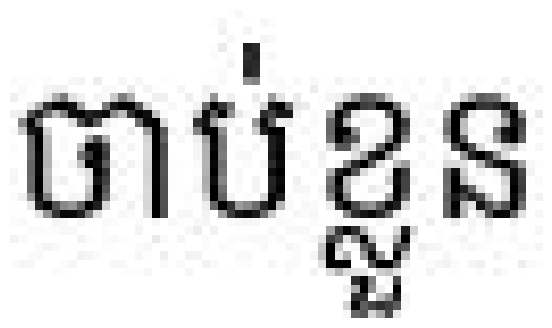

Generated text: ចាប់ខ្លួន


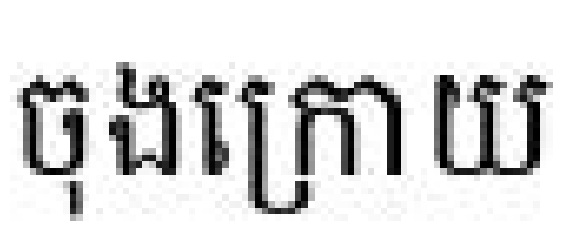

Generated text: ចុងក្រោយ


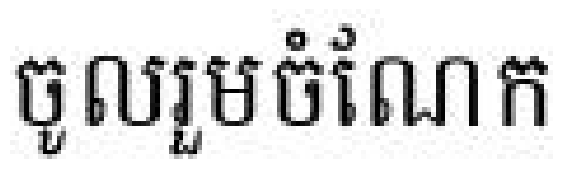

Generated text: ចូលរួមចំណែក


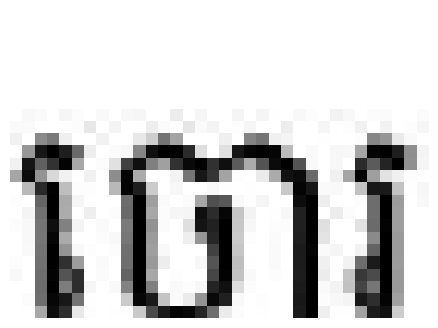

Generated text: ចោរ


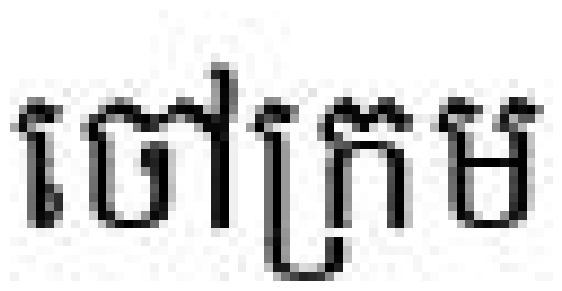

Generated text: ចៅក្រម


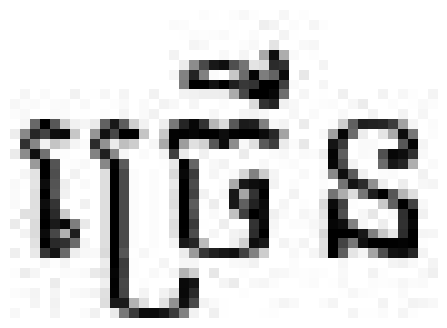

Generated text: ច្រើន


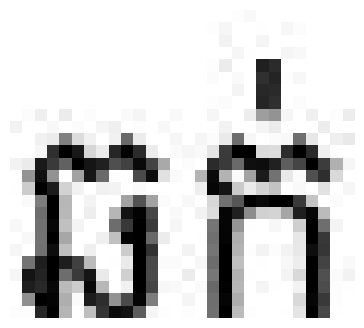

Generated text: ឆក់


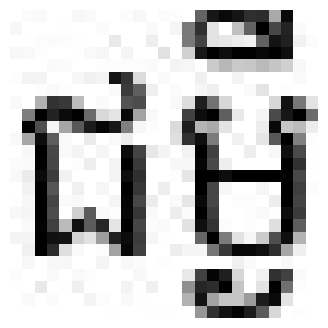

Generated text: ជម្ងឺ


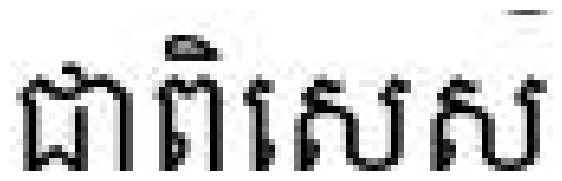

Generated text: ជាពិសេស


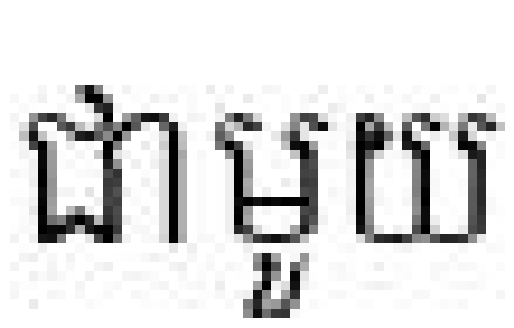

Generated text: ជាមួយ


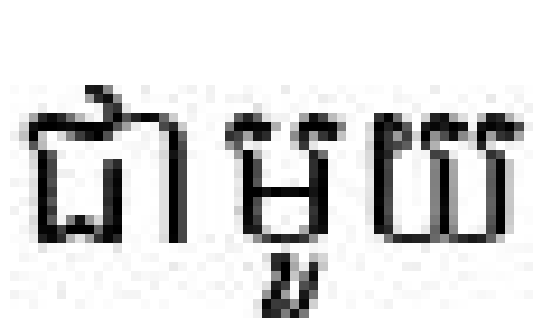

Generated text: ជាមួយ


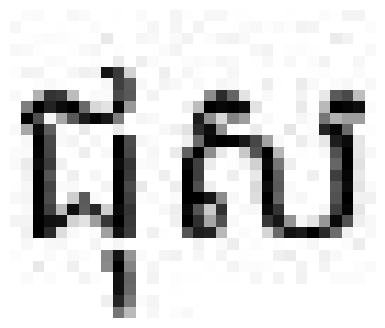

Generated text: ជុស


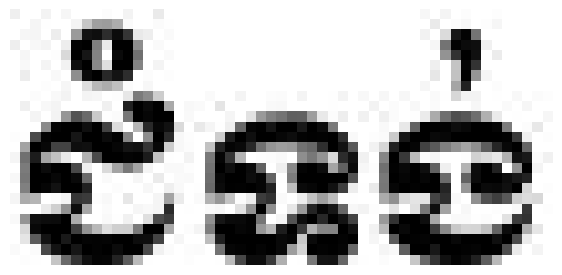

Generated text: ដំង់


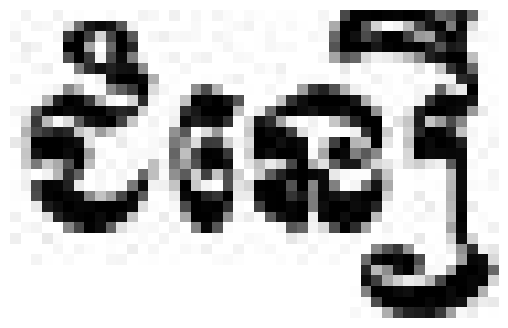

Generated text: ជំនឿ


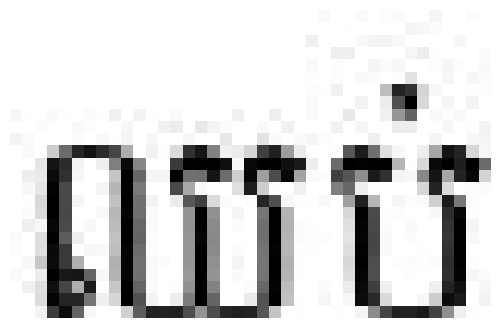

Generated text: ឈប់


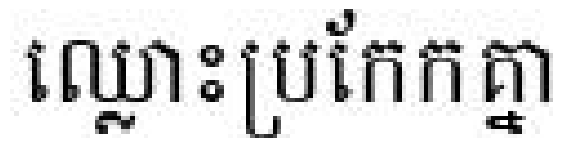

Generated text: ឈ្លោះប្រកែកគ្នា


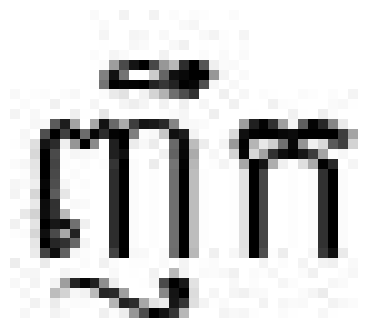

Generated text: ញឹក


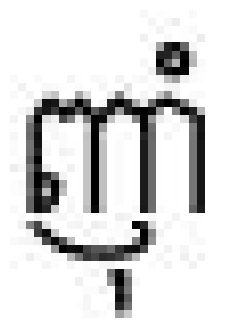

Generated text: ញ៉ាំ


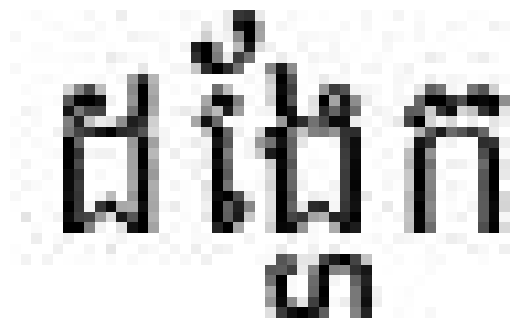

Generated text: ដង្ហែក


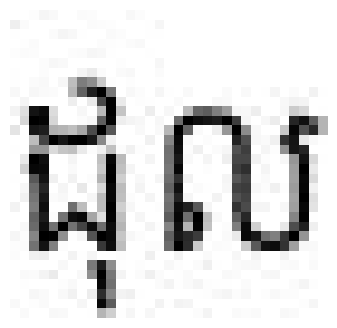

Generated text: ដុល


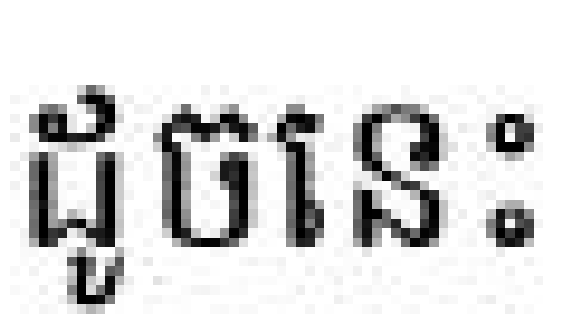

Generated text: ដូចនេះ


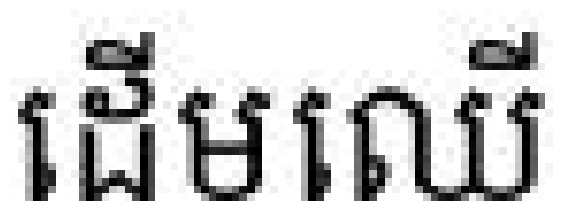

Generated text: ដើមឈើ


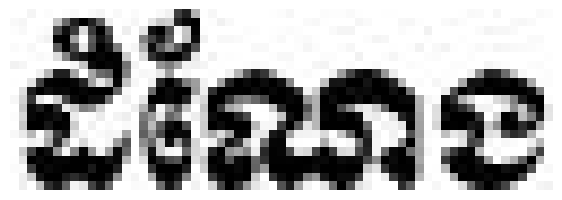

Generated text: ដំណែង


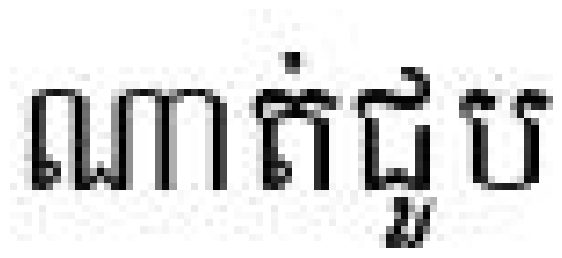

Generated text: ណាត់ជួប


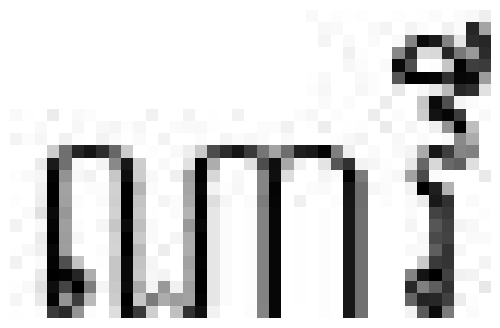

Generated text: ណាវី


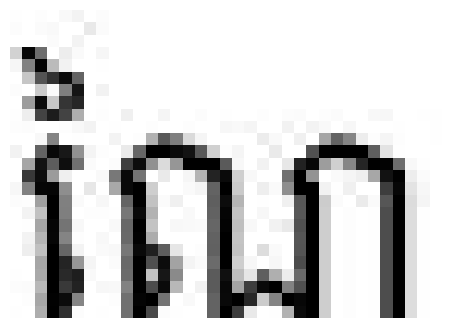

Generated text: រីៃ


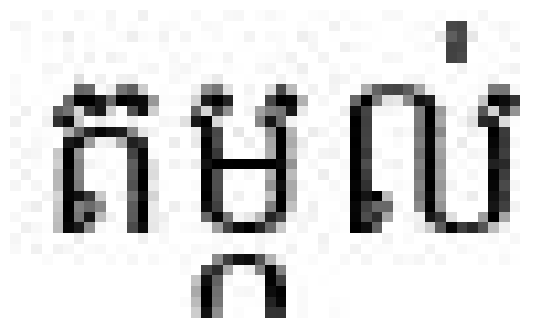

Generated text: តម្កល់


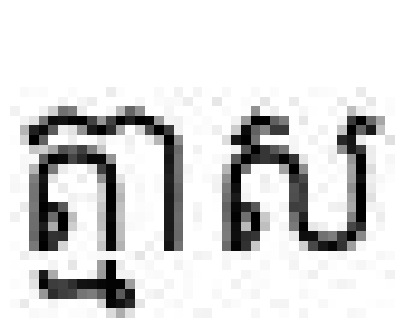

Generated text: ក្នាស


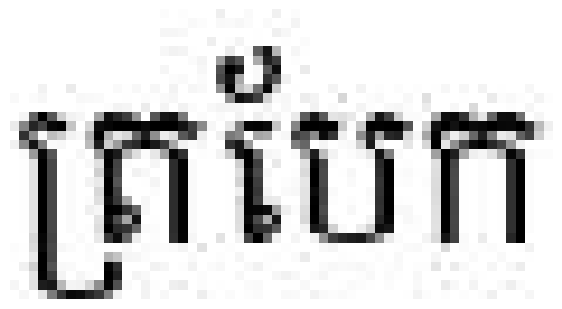

Generated text: ត្របែក


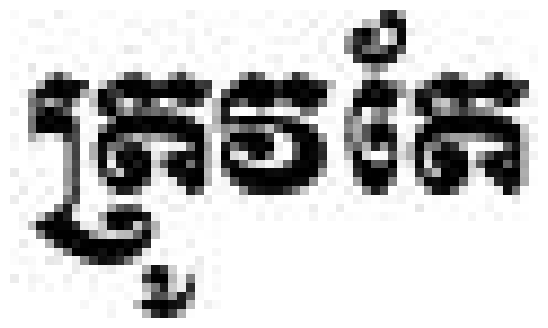

Generated text: ត្រូវតែ


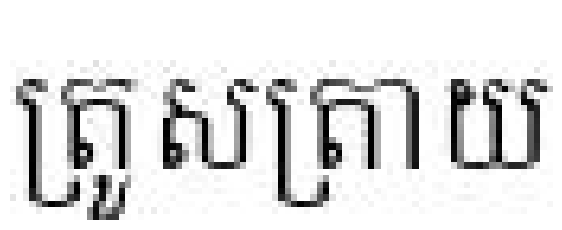

Generated text: ក្រុមក្កាយ


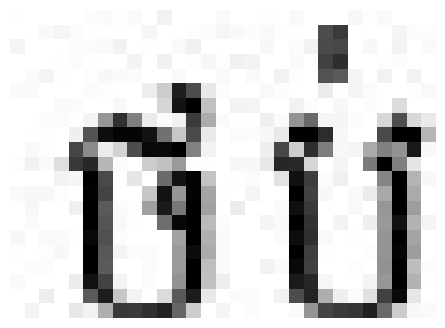

Generated text: ថប់


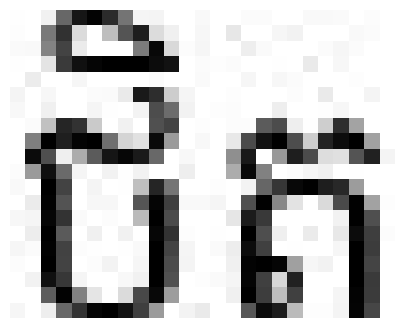

Generated text: ថិត


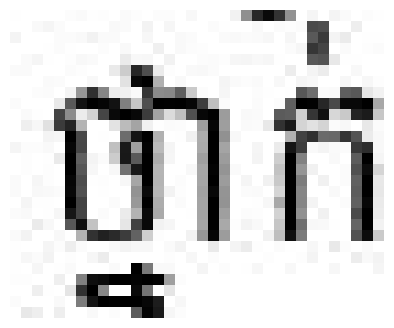

Generated text: ថ្នាក់


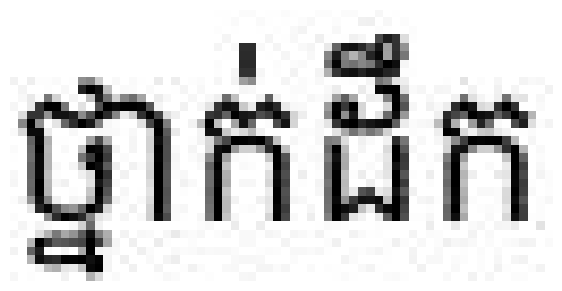

Generated text: ថ្នាក់ដឹកនាំ


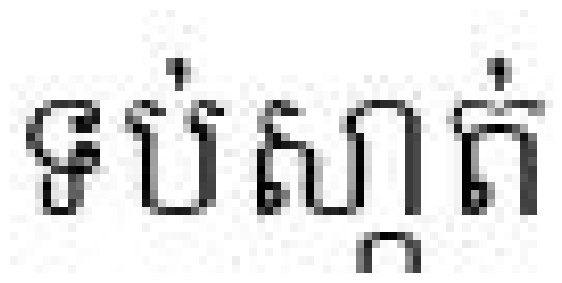

Generated text: ទប់ស្កាត់


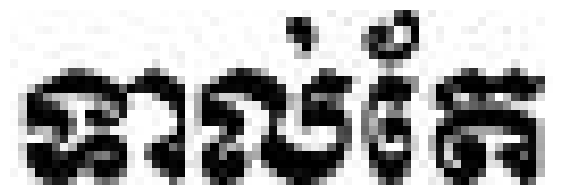

Generated text: ទាន់តែ


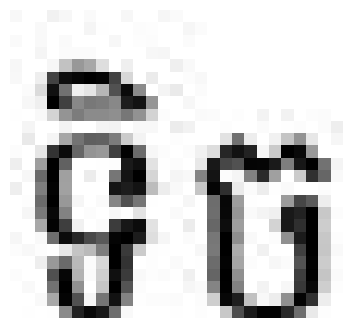

Generated text: ទិច


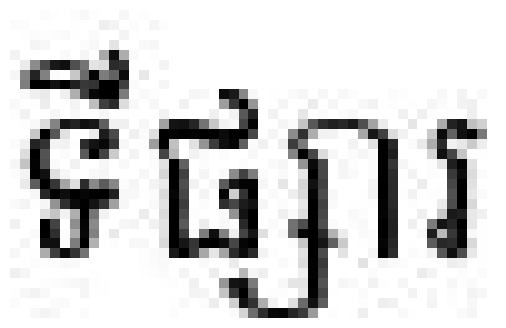

Generated text: ទីផ្សារ


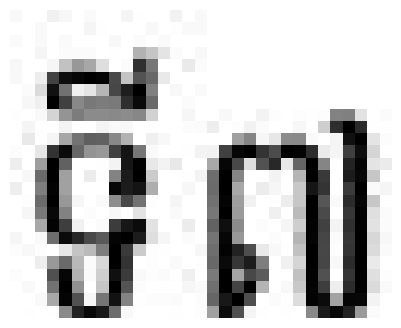

Generated text: ទី៧


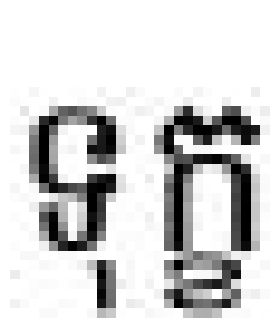

Generated text: ទុក្ខ


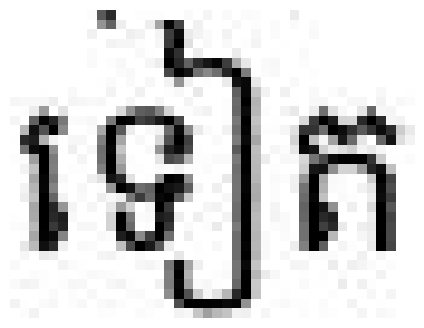

Generated text: ទៀត


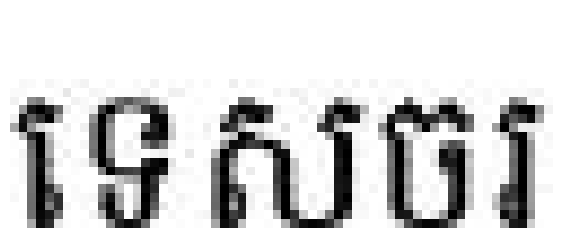

Generated text: ទេសចរ


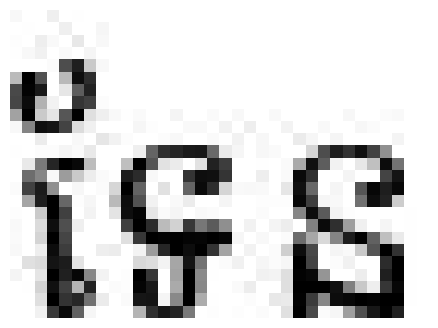

Generated text: ទែន


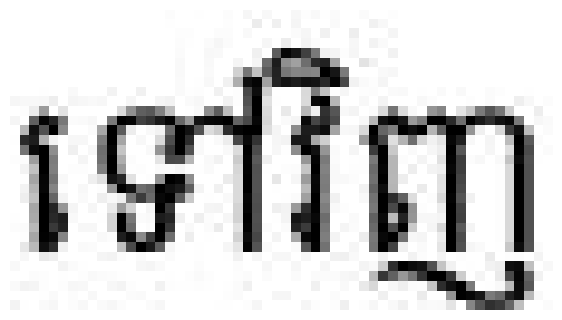

Generated text: ទោវិញ


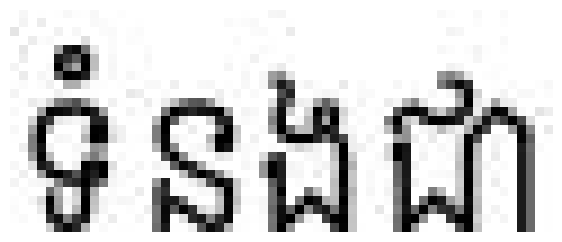

Generated text: ទំនងជា


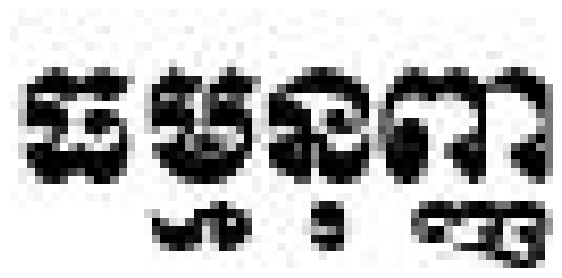

Generated text: ធម្មនុញ្ញ


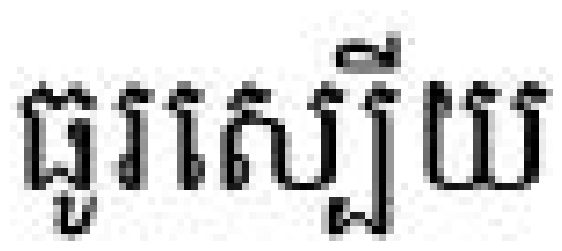

Generated text: ធូរស្្លេយ


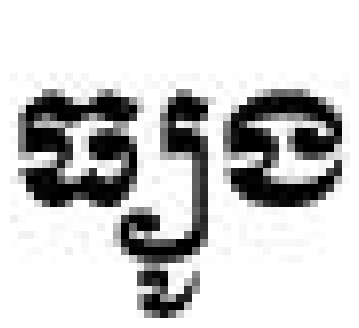

Generated text: ធ្យូង


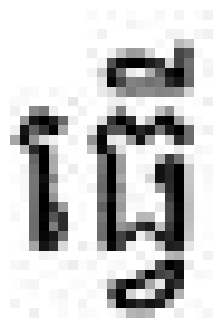

Generated text: ធ្វើ


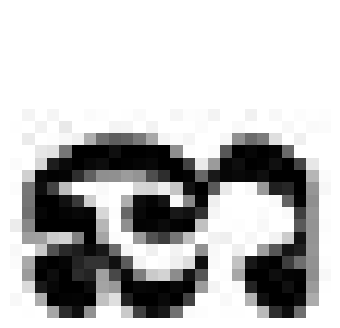

Generated text: នា


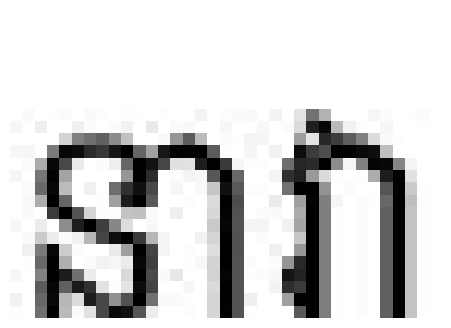

Generated text: នាវា


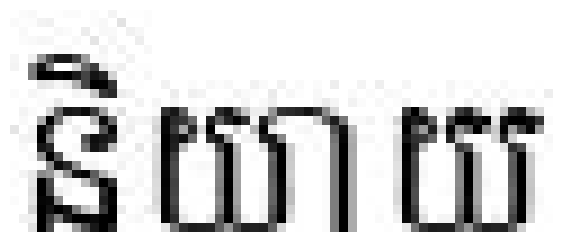

Generated text: និយាយ


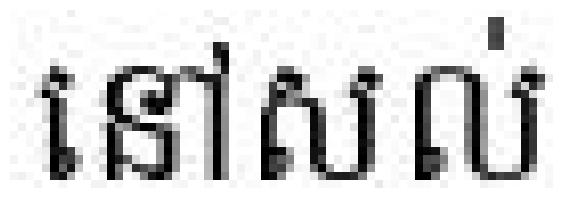

Generated text: នៅសល់


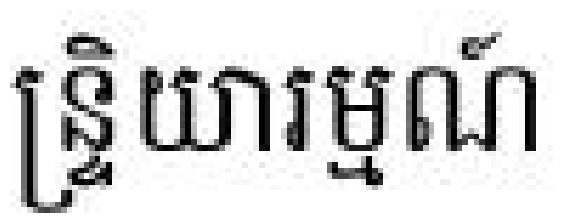

Generated text: ព្រឹទ្ធសភា


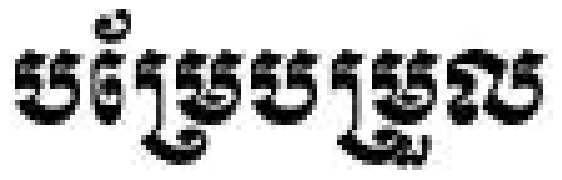

Generated text: ប្រហែលម្ម្ួល


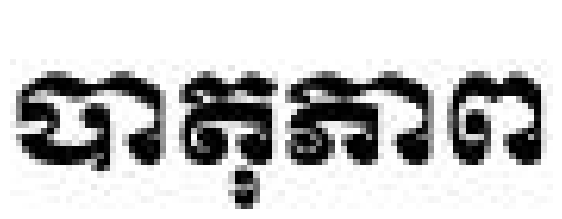

Generated text: បាតតុភាព


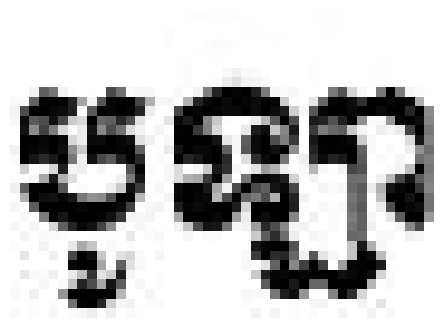

Generated text: បូឡា


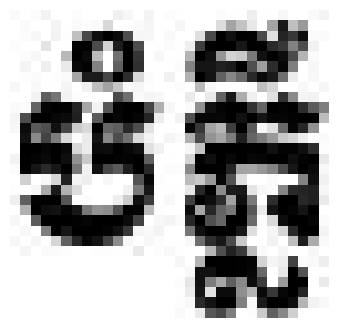

Generated text: បំភ្លឺ


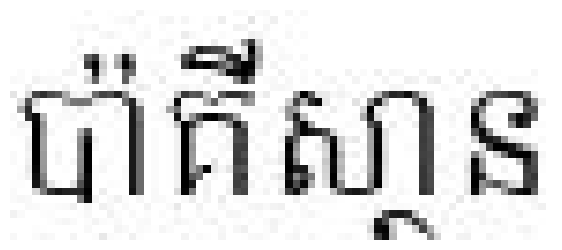

Generated text: ប៉ាគីស្មាន


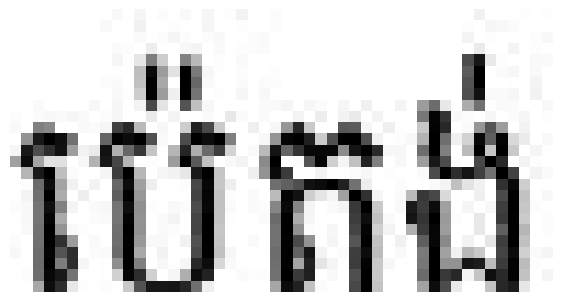

Generated text: ប៉េតង់


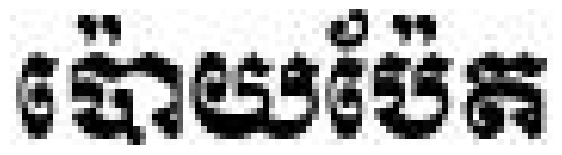

Generated text: ប៉ោយប៉ែត


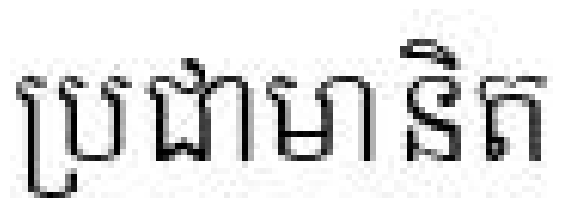

Generated text: ប្រជាមានិត


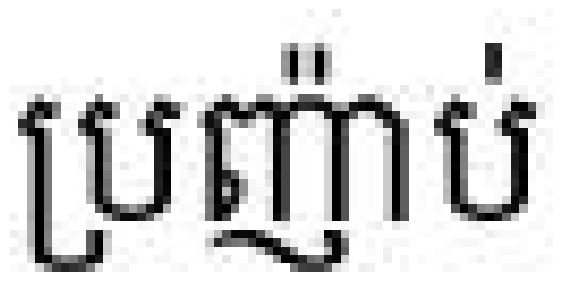

Generated text: ប្រញ៉ាប់


In [25]:
eval_new_data(
    data_path=os.path.join(DatasetConfig.DATA_ROOT, 'data_test', '*'),
    num_samples=300
)